<div style="background:#1f2933;color:#ffffff;padding:28px 32px;border-radius:14px">
<div style="font-size:12px;letter-spacing:3px;color:#a9c4f2">DATA ANALYSIS &nbsp;·&nbsp; STEAM &nbsp;·&nbsp; 125,855 GAMES</div>
<div style="font-size:30px;font-weight:700;margin:8px 0 6px">🎮 What makes a Steam game successful?</div>
<div style="font-size:15px;color:#dfe5ec">Defining success, testing launch-time indicators and predicting hits with SQL and Python</div>
</div>

**🎯 Goal:** define indicators of a successful game, test whether game features go with them, and build a model that predicts success from what is known at launch.
**📄 Data:** [Steam Games Dataset (Kaggle)](https://www.kaggle.com/datasets/fronkongames/steam-games-dataset)

<div style="background:#eaf6f4;border-left:5px solid #2a9d8f;padding:10px 16px;margin:10px 0;border-radius:6px;color:#1f2933;line-height:1.55">
<b style="color:#2a9d8f">👤 About this notebook</b><br>
I made this analysis as part of my <b>data analytics portfolio</b>. It shows how I work end to end: fixing a broken raw file,
modelling the data in SQL, defining a fair target, testing ideas with honest statistics, building and explaining a model,
and presenting the results clearly.<br><br>
<b>Mihail Deligrozev</b> · Data analyst · Python · SQL · Power BI
</div>

## ⭐ Summary

<div style="background:#eef4ff;border-radius:10px;padding:14px 20px;line-height:1.7">
🏆 <b>Success on Steam is winner-takes-most.</b> The top 1% of games hold 80% of all reviews, so success is defined as a top percentile, not "above average".<br>
⚖️ <b>Reach and quality are separate things.</b> Owners and positive-review share are uncorrelated (Spearman 0.00), and only 26% of commercial hits are also well liked.<br>
🧩 <b>Consistent launch-time indicators.</b> More Steam categories, more languages, achievements, a higher price, a longer store description and DLC go with success under all four definitions. RPG is the only genre above average under every definition.<br>
🤖 <b>Launch facts predict success reasonably well.</b> For the strict <code>hit</code> label the model reaches AUC 0.80 on newer games, and its top 10% of predictions contain 43% of the actual hits. A developer's track record adds another +0.03 AUC.<br>
⚠️ <b>These are associations, not causes.</b> Successful games can afford more languages and DLC, so some indicators follow success rather than drive it.
</div>

*Numbers are from the run with default parameters. [Section 8](#s8) and the appendix findings recompute them.*

## 🛠️ How the notebook is built

📄 `games.csv` → 🐼 **pandas** (fix and clean) → 🗄️ **DuckDB** tables → 🧮 **SQL** (join, group, window) → 🐍 **Python** (statistics, models, charts) → 🖼️ **PNG** figures

Each tool does what it is best at. Every chart is also saved as a PNG in `figures/` (on Kaggle: the **Output** tab, plus `figures.zip` at the end).

## 🧭 Contents

| | Section | Question it answers |
|---|---------|---------------------|
| 📦 | [1. Setup and loading](#s1) | Is the data read correctly? |
| 🧹 | [2. Cleaning and features](#s2) | What do we keep and what do we build? |
| 🗄️ | [3. Data model and storage](#s3) | How is the data stored, and how small can it be without losing anything? |
| 🔍 | [4. Exploratory analysis](#s4) | How are attention, quality and price distributed? |
| 🏆 | [5. Defining success](#s5) | What does "successful" mean, and is the label fair to old and new games? |
| 🧪 | [6. Testing indicators](#s6) | Which game features go with success? |
| 🤖 | [7. Modelling](#s7) | How well can launch-time features predict success? |
| 📌 | [8. Findings and limits](#s8) | What did we learn, and what should we not over-claim? |
| 📎 | [Appendices A-D](#sa) | Data profile, stability checks, richer features, owner buckets |

**How to read it:** 🧠 purple boxes explain *why* a step is done, 💡 blue boxes give the computed insight, ⚠️ orange boxes flag caveats. Cells starting with `# Parameters` hold the numbers you are most likely to change. SQL cells start with `%%sql`.

<a id="s1"></a>
## 📦 1. Setup and loading

<div style="background:#f4f0fa;border-left:5px solid #7b5ea7;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#7b5ea7">🧠 Why this step</b><br>The notebook should run on Kaggle and on a laptop without edits. So paths are <b>found</b> rather than hard-coded: the newest attached version of <code>utils.py</code> and the attached <code>games.csv</code> are located automatically. Helper functions live in <code>utils.py</code> so this notebook shows analysis, not plumbing.</div>

In [1]:
# DuckDB (database) and jupysql (%%sql cells) are not preinstalled on Kaggle. Needs Internet on in the notebook settings.
%pip install -q duckdb jupysql

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.1/95.1 kB 930.3 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 192.8/192.8 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 880.2/880.2 kB 9.7 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Make utils.py importable. On Kaggle it is attached as a model; the newest attached version wins.
import glob
import os
import sys

UTILS_ROOT = '/kaggle/input/models/mihaildeligrozev/utils/pytorch/default'
versions = [p for p in glob.glob(f'{UTILS_ROOT}/*/utils.py') if p.split('/')[-2].isdigit()]
if versions:
    newest = max(versions, key=lambda p: int(p.split('/')[-2]))
    sys.path.insert(0, os.path.dirname(newest))
    print('Using', newest)
else:
    print('Using utils.py from the notebook folder')

Using /kaggle/input/models/mihaildeligrozev/utils/pytorch/default/1/utils.py


In [3]:
# Libraries

#Importing libraries
import csv
import shutil
import warnings

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.patches import FancyBboxPatch, Rectangle

from utils import (BLUE, FIG_DIR, GRID, INK, LIGHT_BLUE, MUTED, ORANGE, PALE, PURPLE, TEAL, auc_score, callout,
                   human, lift_plot, lollipop, note, parse_lists, pct, rate_plot, ridgeline, set_style, show,
                   show_md, spearman, titles, waffle, wilson)

warnings.filterwarnings('ignore')
set_style()
print('Charts are saved to', os.path.abspath(FIG_DIR))

Charts are saved to /kaggle/working/figures


In [4]:
# Find games.csv: attached Kaggle dataset first, then a local copy, then download it with kagglehub
kaggle_hits = sorted(glob.glob('/kaggle/input/**/games.csv', recursive=True))
if kaggle_hits:
    data_file = kaggle_hits[0]
elif os.path.exists('games.csv'):
    data_file = 'games.csv'
else:
    import kagglehub
    data_file = os.path.join(kagglehub.dataset_download('fronkongames/steam-games-dataset'), 'games.csv')
print('Reading', data_file)

Reading /kaggle/input/datasets/fronkongames/steam-games-dataset/games.csv


<div style="background:#fff4ea;border-left:5px solid #e8833a;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#e8833a">⚠️ Read with care</b><br>The header of this file has 39 names but every row has 40 values, because two names are glued together (<code>DiscountDLC count</code> is really <code>Discount</code> and <code>DLC count</code>). Without a fix every column after it is shifted by one, so <code>AppID</code> would hold game names. The header is read with <code>csv</code>, split, and passed to pandas.</div>

In [5]:
#Solving the mismatched headrs
with open(data_file, newline='', encoding='utf-8') as f:
    header = next(csv.reader(f))

i = header.index('DiscountDLC count')
col_names = header[:i] + ['Discount', 'DLC count'] + header[i + 1:]

# header=0 skips the broken header row, index_col=False stops pandas using the first column as index
df = pd.read_csv(data_file, header=0, names=col_names, index_col=False)

assert len(col_names) == 40 and df.shape[1] == 40, 'column count mismatch: check the header fix'
print(f'{df.shape[0]:,} rows x {df.shape[1]} columns')

125,855 rows x 40 columns


<a id="s2"></a>
## 🧹 2. Cleaning and feature engineering

<div style="background:#f4f0fa;border-left:5px solid #7b5ea7;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#7b5ea7">🧠 Why this step</b><br>The quality of the data determines the quality of the model. Checking gaps and duplicates first, and writing each cleaning decision into a table, makes every later number traceable. The full column-by-column profile is in [Appendix A](#sa).</div>

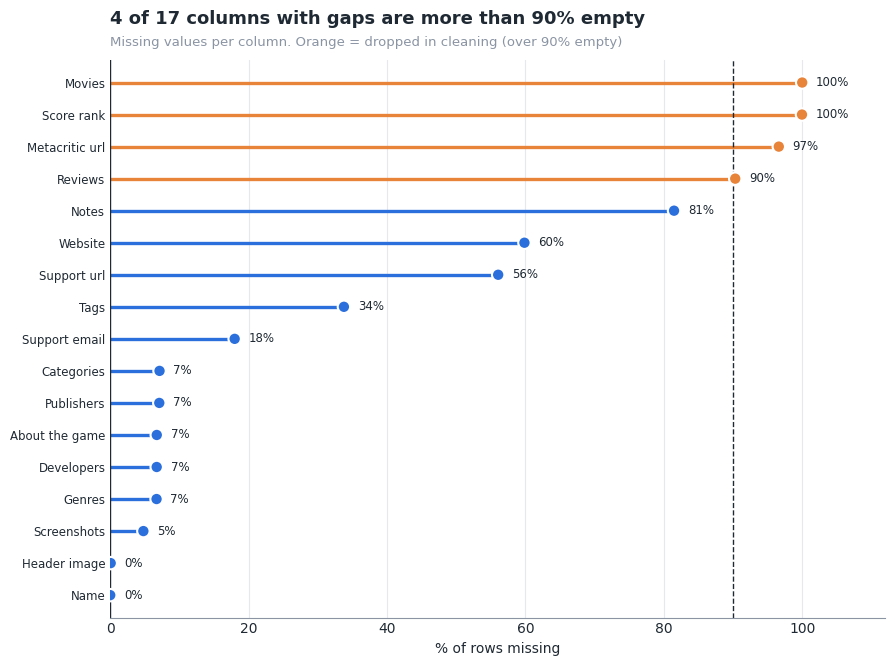

'/kaggle/working/figures/fig01_missing_values.png'

In [6]:
# Missing values per column. Columns past the dashed line are dropped in the cleaning step.
missing = (df.isna().mean() * 100).sort_values()
missing = missing[missing > 0]

missing_treashold = 90

fig, ax = plt.subplots(figsize=(10, 0.32 * len(missing) + 1.8))
lollipop(ax, missing, center=0, fmt='{:.0f}%', colors=[ORANGE if v > missing_treashold else BLUE for v in missing], label_size=8.5)
ax.axvline(missing_treashold, color=INK, lw=1, ls='--')
ax.set_xlim(0, 112)
ax.set_xlabel('% of rows missing')
titles(ax, f'{(missing > 90).sum()} of {len(missing)} columns with gaps are more than 90% empty',
       'Missing values per column. Orange = dropped in cleaning (over 90% empty)')
show(fig, 'fig01_missing_values')

<div style="background:#fff4ea;border-left:5px solid #e8833a;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#e8833a">⚠️ Note </b><br> The 90% is arbitery and it is manualy determied</div>

In [7]:
# Data quality checks: a game listed twice would bias every rate in this notebook
print(f"Duplicate rows:        {df.duplicated().sum():,}")
print(f"Duplicate AppIDs:      {df['AppID'].duplicated().sum():,}")
print(f"Missing game names:    {df['Name'].isna().sum():,}")

Duplicate rows:        0
Duplicate AppIDs:      0
Missing game names:    1


### 🧽 Cleaning steps

| Step | What | Why |
|------|------|-----|
| 1 | Flag `has_website`, then drop columns that are over 90% empty | Almost no information, and the flag keeps the one useful signal from `Website` |
| 2 | Remove duplicate AppIDs and unnamed rows | Avoid double counting |
| 3 | Parse release date and the owners range | `Estimated owners` is text like `"20000 - 50000"` |
| 4 | Build review features | Positive ratio is undefined with zero reviews, so it stays `NaN` |
| 5 | Parse list-like text columns | Genres, tags and languages become real lists |
| 6 | Count and flag features | Simple launch-time signals: languages, platforms, price, text length |

In [8]:
# Steps 1-2: drop mostly empty columns, remove duplicates
df_clean = df.copy()
df_clean['has_website'] = df_clean['Website'].notna()     # must happen before Website can be dropped

# Parameters
MISSING_DROP_PCT = 90

missing_pct = df_clean.isna().mean() * 100
dropped = missing_pct[missing_pct > MISSING_DROP_PCT].round(1)
df_clean = df_clean.drop(columns=dropped.index)
df_clean = df_clean.drop_duplicates(subset='AppID').dropna(subset=['Name'])

print(f'Dropped {len(dropped)} columns: {", ".join(dropped.index)}')
print(f'Rows: {len(df):,} -> {len(df_clean):,}    Columns: {df.shape[1]} -> {df_clean.shape[1]}')

Dropped 4 columns: Reviews, Metacritic url, Score rank, Movies
Rows: 125,855 -> 125,854    Columns: 40 -> 37


In [9]:
# Step 3: dates and owners
df_clean['Release date'] = pd.to_datetime(df_clean['Release date'], errors='coerce', format='mixed')
df_clean['release_year'] = df_clean['Release date'].dt.year

# "20000 - 50000" -> low, high, midpoint. Steam only publishes wide buckets, so the midpoint is an estimate.
owners = df_clean['Estimated owners'].astype(str).str.extract(r'(\d+)\s*-\s*(\d+)').astype(float)
df_clean['owners_low'], df_clean['owners_high'] = owners[0], owners[1]
df_clean['owners_mid'] = owners.mean(axis=1)

# Step 4: review features. Ratio is NaN (not 0) when there are no reviews.
df_clean['total_reviews'] = df_clean['Positive'] + df_clean['Negative']
df_clean['positive_ratio'] = (df_clean['Positive'] / df_clean['total_reviews']).where(df_clean['total_reviews'] > 0)

print('Missing release dates:', df_clean['Release date'].isna().sum())
print('Missing owners:       ', df_clean['owners_mid'].isna().sum())

Missing release dates: 0
Missing owners:        0


In [10]:
# Step 5: list-like text -> python lists (parse_lists is in utils.py)
for col in ['Supported languages', 'Full audio languages', 'Categories', 'Genres', 'Tags']:
    df_clean[col + '_list'] = parse_lists(df_clean[col])

In [11]:
# Step 6: counts and flags known at (or near) launch
for c in ['Windows', 'Mac', 'Linux']:       # force real booleans, text "True"/"False" would break sums
    df_clean[c] = df_clean[c].astype(str).str.lower().eq('true')

df_clean['n_languages'] = df_clean['Supported languages_list'].map(len)
df_clean['n_audio_languages'] = df_clean['Full audio languages_list'].map(len)
df_clean['n_genres'] = df_clean['Genres_list'].map(len)
df_clean['n_categories'] = df_clean['Categories_list'].map(len)
df_clean['n_tags'] = df_clean['Tags_list'].map(len)          # EDA only: tags are voted by players, so it leaks success
df_clean['n_platforms'] = df_clean[['Windows', 'Mac', 'Linux']].sum(axis=1)
df_clean['is_free'] = df_clean['Price'] == 0
df_clean['has_achievements'] = df_clean['Achievements'] > 0
df_clean['has_dlc'] = df_clean['DLC count'] > 0
df_clean['about_length'] = df_clean['About the game'].fillna('').str.len()

print(f'{len(df_clean):,} rows, {df_clean.shape[1]} columns')
df_clean[['Name', 'release_year', 'owners_mid', 'Peak CCU', 'total_reviews', 'positive_ratio', 'Price']].head()

125,854 rows, 58 columns


,Name,release_year,owners_mid,Peak CCU,total_reviews,positive_ratio,Price
0,Black Dragon Mage Playtest,2023,0.000,0,0,NaN,0.000
1,Supipara - Chapter 1 Spring Has Come!,2016,"10,000.000",0,255,0.988,5.240
2,Mystery Solitaire The Black Raven,2019,"10,000.000",0,24,0.875,4.990
3,버튜버 파라노이아 - Vtuber Paranoia,2024,"10,000.000",1,0,NaN,8.990
4,Maze Quest VR,2025,"10,000.000",0,0,NaN,4.990


<a id="s3"></a>
## 🗄️ 3. Data model and storage (DuckDB)

<div style="background:#f4f0fa;border-left:5px solid #7b5ea7;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#7b5ea7">🧠 Why this step</b><br>Some questions are simplier to answer using SQL: success rate per genre is a join and a <code>GROUP BY</code>, and "how did this studio's earlier games do?" is a window function. Storing the data as proper tables in DuckDB (a database that runs inside Python, no server needed) makes those queries possible and shows how the data would live in a warehouse.</div>

The cleaned data is stored as a small relational model in a DuckDB file (`steam.duckdb`). DuckDB runs inside Python, needs no server and reads pandas DataFrames directly.

```
games          one row per game            app_id (key), name, release_day, release_year, price,
                                           owners_low / high / mid, peak_ccu, total_reviews, positive_ratio,
                                           recommendations, median_playtime, developers, publishers
game_genres    one row per game and genre  app_id -> games, genre
game_tags      one row per game and tag    app_id -> games, tag
labels         one row per game            app_id -> games, success labels, in_study   (added in section 5)
```

**Why separate genre and tag tables:** a game has several genres. In pandas that is a list inside a cell; in SQL it is a bridge table, so "success rate per genre" becomes a plain join and `GROUP BY`.
**Why `release_day`:** dates are stored as days since 1970, so "released at least a year earlier" is simple arithmetic in a window function (Appendix C).

In [12]:
# Tables for the database: snake_case names, one value per cell
games_tbl = pd.DataFrame({
    'app_id': df_clean['AppID'],
    'name': df_clean['Name'],
    'release_day': (df_clean['Release date'] - pd.Timestamp('1970-01-01')).dt.days.clip(lower=0),
    'release_year': df_clean['release_year'],
    'price': df_clean['Price'],
    'owners_low': df_clean['owners_low'],
    'owners_high': df_clean['owners_high'],
    'owners_mid': df_clean['owners_mid'],
    'peak_ccu': df_clean['Peak CCU'],
    'total_reviews': df_clean['total_reviews'],
    'positive_ratio': df_clean['positive_ratio'],
    'recommendations': df_clean['Recommendations'],
    'median_playtime': df_clean['Median playtime forever'],
    'developers': df_clean['Developers'],
    'publishers': df_clean['Publishers'],
})


def bridge(list_col, name):
    """List column -> one row per (game, value). A value listed twice for the same game is kept once."""
    out = df_clean[['AppID', list_col]].explode(list_col).dropna()
    out.columns = ['app_id', name]
    return out.drop_duplicates()


game_genres = bridge('Genres_list', 'genre')
game_tags = bridge('Tags_list', 'tag')

### 💾 3.1 Storage optimisation

<div style="background:#f4f0fa;border-left:5px solid #7b5ea7;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#7b5ea7">🧠 Why this step</b><br>pandas stores every number as 64-bit and every text value as a separate Python string by default. That is safe but wasteful: an AppID fits in 32 bits, a release year in 16, and "Indie" repeated 70,000 times can be stored once as a <b>category</b>. Smaller tables load faster, cost less to store and fit in memory on smaller machines, which matters once data lives in a warehouse or is shipped between teams.<br><br>The rule here is <b>lossless only</b>: a column is only changed if every value survives the round trip, and this is checked. Prices are kept as 64-bit floats on purpose, because 32-bit floats would turn 4.99 into 4.9899998.</div>

In [13]:
# Optimise column types without changing any value
def optimise(frame, max_unique_share=0.5):
    '''Return a smaller copy of `frame` plus a log of what changed. Only lossless changes are kept.'''
    out = frame.copy()
    for col in out.columns:
        s = out[col]
        if pd.api.types.is_bool_dtype(s) or s.map(type).eq(list).any():
            continue                                                     # flags are already 1 byte; lists cannot be compressed this way
        if pd.api.types.is_integer_dtype(s):
            out[col] = pd.to_numeric(s, downcast='integer')              # int64 -> int8 / int16 / int32
        elif pd.api.types.is_float_dtype(s):
            whole = s.dropna()
            if len(whole) and (whole == np.floor(whole)).all() and whole.abs().max() < 2**31:
                smallest = pd.to_numeric(whole, downcast='integer').dtype.name
                out[col] = s.astype(smallest.capitalize())               # whole numbers stored as float -> nullable integer
        elif (s.dtype == object or pd.api.types.is_string_dtype(s)) and s.nunique() / max(len(s), 1) < max_unique_share:
            out[col] = s.astype('category')                              # repeated text -> category codes
    return out


def same_values(a, b):
    '''True if two columns hold the same values (NaN equals NaN), whatever their types.'''
    if isinstance(b.dtype, pd.CategoricalDtype):
        b = b.astype(object)
    if pd.api.types.is_numeric_dtype(a) and not pd.api.types.is_bool_dtype(a):
        a, b = a.astype('float64'), b.astype('float64')
    return bool(((a == b) | (a.isna() & b.isna())).all())


def mb(frame):
    return frame.memory_usage(deep=True).sum() / 1e6


tables = {'Raw file (40 columns)': df, 'games': games_tbl, 'game_genres': game_genres, 'game_tags': game_tags}
optimised, rows, changes = {}, [], []
for name, frame in tables.items():
    opt = optimise(frame)
    bad = [c for c in frame.columns if not same_values(frame[c], opt[c])]
    assert not bad, f'{name}: values changed in {bad}'
    optimised[name] = opt
    rows.append({'table': name, 'before_mb': mb(frame), 'after_mb': mb(opt)})
    changes += [{'table': name, 'column': c, 'before': str(frame[c].dtype), 'after': str(opt[c].dtype)}
                for c in frame.columns if str(frame[c].dtype) != str(opt[c].dtype)]
memory = pd.DataFrame(rows).set_index('table')
memory['saved_%'] = (1 - memory['after_mb'] / memory['before_mb']) * 100

# The stored tables use the optimised types from here on; the analysis keeps df_clean at full precision
games_tbl, game_genres, game_tags = optimised['games'], optimised['game_genres'], optimised['game_tags']
print(f'All {len(tables)} tables passed the lossless check. Type changes made:')
pd.DataFrame(changes).groupby(['table', 'before', 'after']).size().rename('columns').reset_index()

All 4 tables passed the lossless check. Type changes made:


,table,before,after,columns
0,Raw file (40 columns),float64,Int8,1
1,Raw file (40 columns),int64,int16,4
2,Raw file (40 columns),int64,int32,7
3,Raw file (40 columns),int64,int8,4
4,Raw file (40 columns),object,category,12
5,game_genres,int64,int32,1
6,game_genres,object,category,1
7,game_tags,int64,int32,1
8,game_tags,object,category,1
9,games,float64,Int32,3


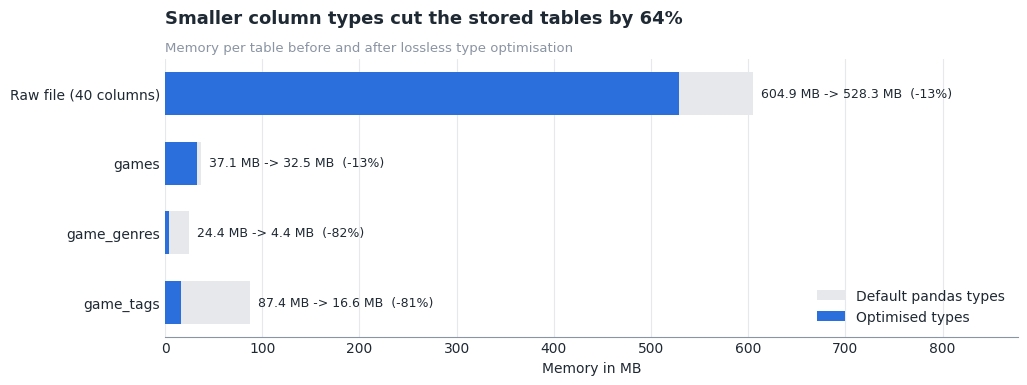

'/kaggle/working/figures/fig_storage_memory.png'

In [14]:
fig, ax = plt.subplots(figsize=(11, 3.6))
y = np.arange(len(memory))[::-1]
ax.barh(y, memory['before_mb'], color=GRID, height=0.62, label='Default pandas types')
ax.barh(y, memory['after_mb'], color=BLUE, height=0.62, label='Optimised types')
for yi, (_, r) in zip(y, memory.iterrows()):
    ax.text(r['before_mb'], yi, f"  {r['before_mb']:,.1f} MB -> {r['after_mb']:,.1f} MB  (-{r['saved_%']:.0f}%)",
            va='center', fontsize=9)
ax.set_yticks(y)
ax.set_yticklabels(memory.index)
ax.set_xlim(0, memory['before_mb'].max() * 1.45)
ax.set_xlabel('Memory in MB')
ax.legend(loc='lower right')
ax.grid(axis='y', visible=False)
stored = memory.drop('Raw file (40 columns)')
titles(ax, f"Smaller column types cut the stored tables by {(1 - stored['after_mb'].sum() / stored['before_mb'].sum()):.0%}",
       'Memory per table before and after lossless type optimisation')
show(fig, 'fig_storage_memory')

In [15]:
# Write the tables to the DuckDB file. CREATE OR REPLACE makes the cell safe to rerun.
con = duckdb.connect('steam.duckdb')


def save_table(name, frame):
    # Categories go in as plain text: DuckDB compresses repeated strings itself, and plain text keeps SQL simple
    frame = frame.astype({c: 'object' for c in frame.select_dtypes('category').columns})
    con.register('tmp_frame', frame)
    con.execute(f'CREATE OR REPLACE TABLE {name} AS SELECT * FROM tmp_frame')
    con.unregister('tmp_frame')


for name, frame in {'games': games_tbl, 'game_genres': game_genres, 'game_tags': game_tags}.items():
    save_table(name, frame)

# %%sql cells run on this connection and return pandas DataFrames
%load_ext sql
%sql con --alias steam
%config SqlMagic.autopandas = True
%config SqlMagic.displaycon = False
%config SqlMagic.feedback = 0

### 📦 3.2 Which file format?

<div style="background:#f4f0fa;border-left:5px solid #7b5ea7;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#7b5ea7">🧠 Why this step</b><br>Memory is one side; the file on disk is the other. CSV is readable everywhere but stores numbers as text and has no types. <b>Parquet</b> stores each column together, compressed and typed, which is why data lakes use it. <b>DuckDB</b> keeps everything in one compressed database file that SQL can query directly. The same three tables are written in each format and read back, to compare size and speed.</div>

In [16]:
# Write the stored tables in several formats, then measure size on disk and time to read them back
import time

con.execute('CHECKPOINT')            # flush DuckDB's write-ahead log so the file size is final
os.makedirs('storage_test', exist_ok=True)
stored_tables = {'games': games_tbl, 'game_genres': game_genres, 'game_tags': game_tags}

formats = {
    'CSV': ('.csv', lambda f, p: f.to_csv(p, index=False), pd.read_csv),
    'CSV + gzip': ('.csv.gz', lambda f, p: f.to_csv(p, index=False, compression='gzip'), pd.read_csv),
    'Parquet (snappy)': ('.snappy.parquet', lambda f, p: f.to_parquet(p, compression='snappy'), pd.read_parquet),
    'Parquet (zstd)': ('.zstd.parquet', lambda f, p: f.to_parquet(p, compression='zstd'), pd.read_parquet),
}
results = []
for fmt, (ext, write, read) in formats.items():
    try:
        paths = []
        for name, frame in stored_tables.items():
            path = os.path.join('storage_test', name + ext)
            write(frame, path)
            paths.append(path)
        t0 = time.perf_counter()
        for p in paths:
            read(p)
        results.append({'format': fmt, 'size_mb': sum(os.path.getsize(p) for p in paths) / 1e6,
                        'read_s': time.perf_counter() - t0})
    except Exception as e:                       # e.g. no Parquet engine installed
        print(f'{fmt} skipped: {type(e).__name__}: {e}')

if os.path.exists('steam.duckdb') and os.path.getsize('steam.duckdb') > 0:
    t0 = time.perf_counter()
    for name in stored_tables:
        con.execute(f'SELECT * FROM {name}').df()
    results.append({'format': 'DuckDB file', 'size_mb': os.path.getsize('steam.duckdb') / 1e6,
                    'read_s': time.perf_counter() - t0})

storage = pd.DataFrame(results).set_index('format').sort_values('size_mb')
storage['vs_csv'] = storage['size_mb'] / storage.loc['CSV', 'size_mb']
original_mb = os.path.getsize(data_file) / 1e6
storage

,size_mb,read_s,vs_csv
format,,,
Parquet (zstd),10.193,0.190,0.258
CSV + gzip,11.192,1.093,0.283
DuckDB file,12.595,0.361,0.319
Parquet (snappy),12.982,0.330,0.328
CSV,39.525,0.859,1.000


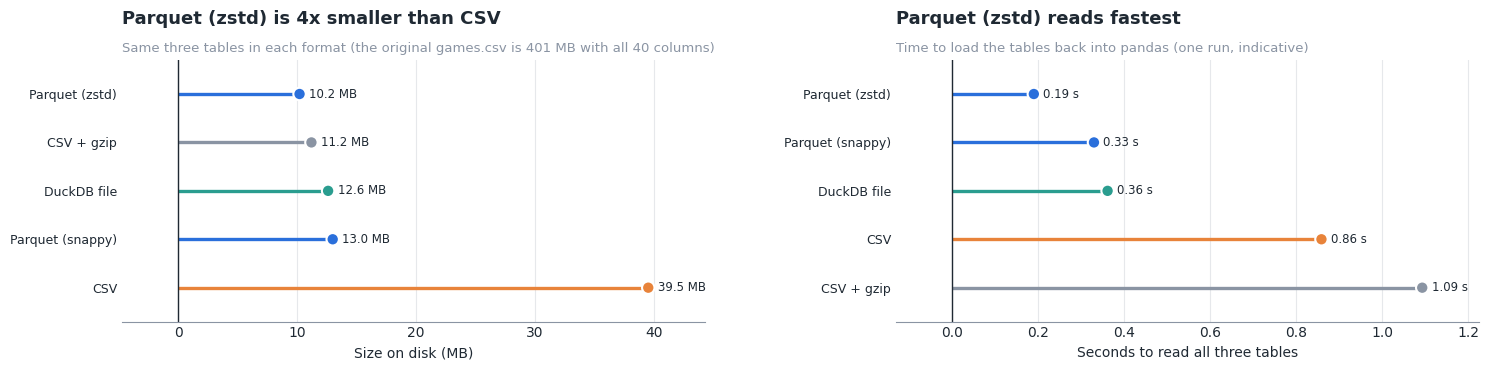

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(15, 3.8))
order = storage.sort_values('size_mb', ascending=False)
lollipop(ax[0], order['size_mb'], center=0, fmt='{:,.1f} MB',
         colors=[ORANGE if 'CSV' == f else BLUE if 'Parquet' in f else TEAL if 'DuckDB' in f else MUTED for f in order.index])
ax[0].set_xlabel('Size on disk (MB)')
titles(ax[0], f"{order.index[-1]} is {1 / order['vs_csv'].iloc[-1]:.0f}x smaller than CSV",
       f'Same three tables in each format (the original games.csv is {original_mb:,.0f} MB with all 40 columns)')

order_t = storage.sort_values('read_s', ascending=False)
lollipop(ax[1], order_t['read_s'], center=0, fmt='{:.2f} s',
         colors=[ORANGE if 'CSV' == f else BLUE if 'Parquet' in f else TEAL if 'DuckDB' in f else MUTED for f in order_t.index])
ax[1].set_xlabel('Seconds to read all three tables')
titles(ax[1], f'{order_t.index[-1]} reads fastest', 'Time to load the tables back into pandas (one run, indicative)')
plt.tight_layout()
show(fig, 'fig_storage_formats')

csv_mb, best = storage.loc['CSV', 'size_mb'], storage['size_mb'].idxmin()
note(f'**Insight:** lossless type changes cut the stored tables from **{stored["before_mb"].sum():,.1f} MB** to '
     f'**{stored["after_mb"].sum():,.1f} MB** in memory. On disk the same tables take **{csv_mb:,.1f} MB** as CSV and '
     f'**{storage.loc[best, "size_mb"]:,.1f} MB** as {best} ({1 / storage.loc[best, "vs_csv"]:.0f}x smaller), and columnar formats also keep the types, '
     'so nothing has to be parsed again on load.')
callout('Read times come from a single run and vary between machines; the size differences are the robust result. '
        'Category types also need care: joining or concatenating two categoricals with different categories silently falls back to text.', 'caution')

In [18]:
%%sql
-- Size of each table, and how many genres / tags a game has on average
SELECT 'games' AS table_name, COUNT(*) AS n_rows, NULL AS values_per_game
FROM games
UNION ALL
SELECT 'game_genres', COUNT(*), ROUND(COUNT(*) * 1.0 / COUNT(DISTINCT app_id), 2)
FROM game_genres
UNION ALL
SELECT 'game_tags', COUNT(*), ROUND(COUNT(*) * 1.0 / COUNT(DISTINCT app_id), 2)
FROM game_tags

,table_name,n_rows,values_per_game
0,games,125854,NaN
1,game_genres,338583,2.880
2,game_tags,1180141,14.160


<a id="s4"></a>
## 🔍 4. Exploratory data analysis

Most Steam games get almost no attention, so every attention metric is extremely right-skewed. The first charts show how skewed, and the later ones check that the candidate success metrics agree with each other.

<div style="background:#f4f0fa;border-left:5px solid #7b5ea7;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#7b5ea7">🧠 Why this step</b><br>"Successful" only means something against a baseline. Before defining it we need to know what a typical game looks like, how unequal attention is, and whether different success metrics tell the same story.</div>

### 📈 4.1 Distributions

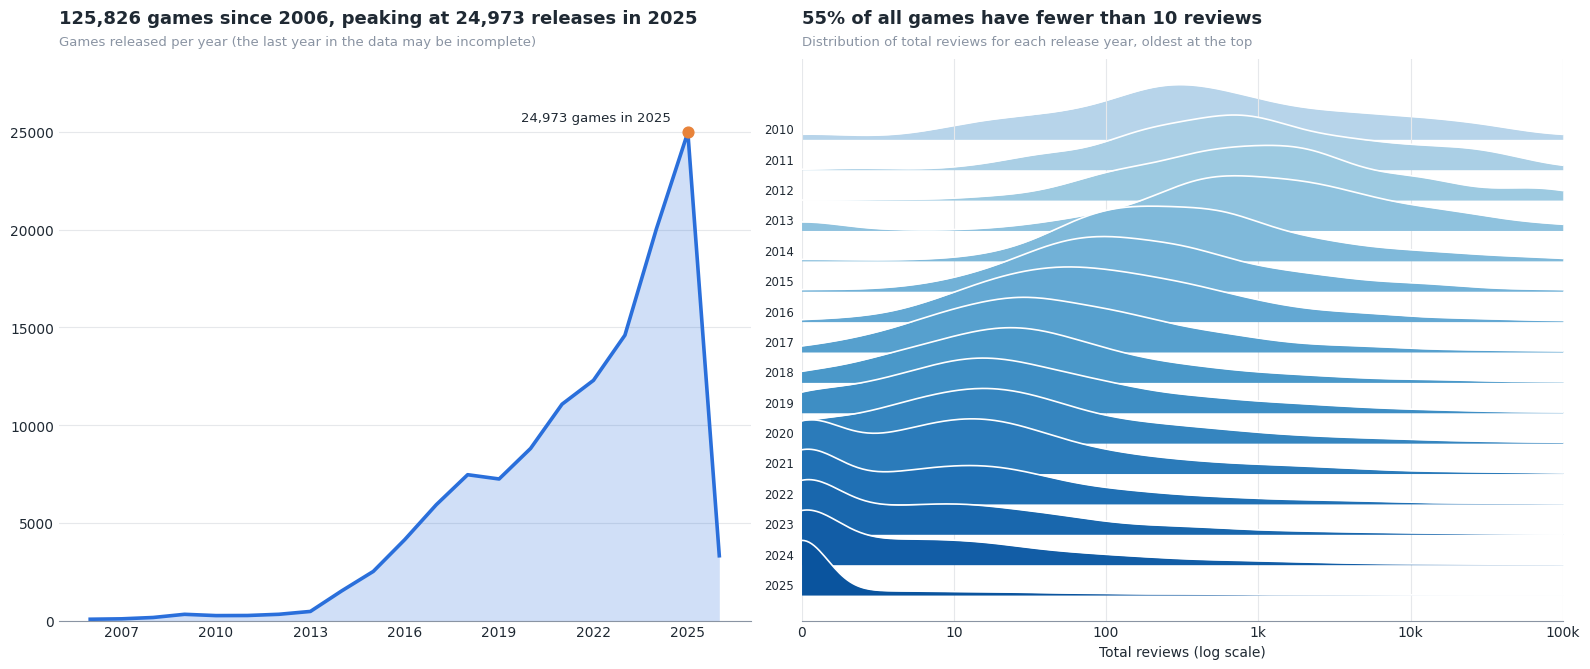

'/kaggle/working/figures/fig02_releases_and_reviews_by_year.png'

In [19]:
# Releases per year, and the full review distribution for every release year (ridgeline)
yearly = df_clean['release_year'].dropna().astype(int).value_counts().sort_index()
yearly = yearly[yearly.index >= 2006]
peak = int(yearly.idxmax())
few_reviews = (df_clean['total_reviews'] < 10).mean()

fig, ax = plt.subplots(1, 2, figsize=(16, 6.8), gridspec_kw={'width_ratios': [1, 1.1]})

ax[0].fill_between(yearly.index, yearly.values, color=BLUE, alpha=0.22, lw=0)
ax[0].plot(yearly.index, yearly.values, color=BLUE, lw=2.6)
ax[0].scatter([peak], [yearly.max()], color=ORANGE, s=60, zorder=3)
ax[0].annotate(f'{yearly.max():,} games in {peak}', (peak, yearly.max()), xytext=(-12, 8),
               textcoords='offset points', ha='right', fontsize=9.5)
ax[0].set_ylim(0, yearly.max() * 1.15)
ax[0].grid(axis='x', visible=False)
ax[0].xaxis.set_major_locator(plt.MaxNLocator(integer=True))
titles(ax[0], f'{yearly.sum():,} games since {yearly.index[0]}, peaking at {yearly.max():,} releases in {peak}',
       'Games released per year (the last year in the data may be incomplete)')

years = [y for y in yearly.index if y >= 2010]
groups = {y: np.log10(df_clean.loc[df_clean['release_year'] == y, 'total_reviews'] + 1) for y in years}
ridgeline(ax[1], groups, (0, 5))
ax[1].set_xticks(range(6))
ax[1].set_xticklabels(['0', '10', '100', '1k', '10k', '100k'])
ax[1].set_xlabel('Total reviews (log scale)')
titles(ax[1], f'{pct(few_reviews, 0)} of all games have fewer than 10 reviews',
       'Distribution of total reviews for each release year, oldest at the top')
plt.tight_layout()
show(fig, 'fig02_releases_and_reviews_by_year')

<div style="background:#eef4ff;border-left:5px solid #2a6fdb;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#2a6fdb">📌 Note</b><br>A <b>ridgeline plot</b> stacks one density curve per year. It shows the whole distribution instead of one average, so you can see that the shape barely changes: every year produces a big mass of games with almost no reviews and a long thin tail of hits.</div>

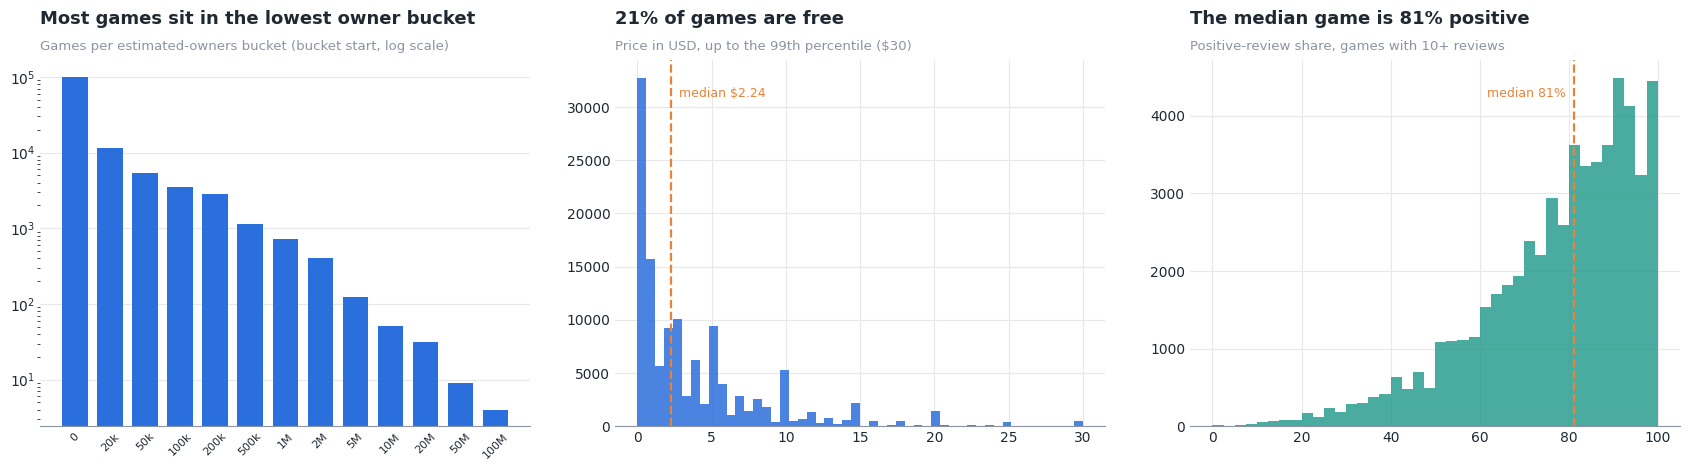

'/kaggle/working/figures/fig03_owners_price_reviews.png'

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))

owner_counts = df_clean.groupby('owners_low').size().sort_index()
ax[0].bar(range(len(owner_counts)), owner_counts.values, color=BLUE, width=0.72)
ax[0].set_yscale('log')
ax[0].set_xticks(range(len(owner_counts)))
ax[0].set_xticklabels([human(v) for v in owner_counts.index], rotation=45, fontsize=8)
ax[0].grid(axis='x', visible=False)
titles(ax[0], 'Most games sit in the lowest owner bucket', 'Games per estimated-owners bucket (bucket start, log scale)')

cap = df_clean['Price'].quantile(0.99)
prices = df_clean.loc[df_clean['Price'] <= cap, 'Price']
ax[1].hist(prices, bins=50, color=BLUE, alpha=0.85)
ax[1].axvline(prices.median(), color=ORANGE, lw=1.6, ls='--')
ax[1].text(prices.median(), ax[1].get_ylim()[1] * 0.9, f'  median ${prices.median():.2f}', color=ORANGE, fontsize=9)
titles(ax[1], f'{pct(df_clean["is_free"].mean(), 0)} of games are free', f'Price in USD, up to the 99th percentile (${cap:.0f})')

well = df_clean.loc[df_clean['total_reviews'] >= 10, 'positive_ratio'] * 100
ax[2].hist(well, bins=40, color=TEAL, alpha=0.85)
ax[2].axvline(well.median(), color=ORANGE, lw=1.6, ls='--')
ax[2].text(well.median(), ax[2].get_ylim()[1] * 0.9, f'median {well.median():.0f}%  ', color=ORANGE, fontsize=9, ha='right')
titles(ax[2], f'The median game is {well.median():.0f}% positive', 'Positive-review share, games with 10+ reviews')
plt.tight_layout()
show(fig, 'fig03_owners_price_reviews')

### 🏔️ 4.2 How concentrated is attention?

<div style="background:#f4f0fa;border-left:5px solid #7b5ea7;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#7b5ea7">🧠 Why this step</b><br>If attention were spread evenly, "above average" would be a sensible definition of success. If a few games take almost everything, a top-percentile definition is needed. One SQL query measures the thresholds; a second builds the <b>Lorenz curve</b> (cumulative share of reviews against share of games), the standard picture of inequality.</div>

In [21]:
%%sql attention <<
WITH ranked AS (
    SELECT *,
           ROW_NUMBER() OVER (ORDER BY total_reviews DESC) AS review_rank,   -- 1 = most reviewed game
           COUNT(*) OVER ()                                AS n_games,
           SUM(total_reviews) OVER ()                      AS all_reviews
    FROM games
)
SELECT
    AVG(CASE WHEN total_reviews = 0     THEN 1.0 ELSE 0 END) AS no_reviews,
    AVG(CASE WHEN total_reviews >= 10   THEN 1.0 ELSE 0 END) AS reviews_10,
    AVG(CASE WHEN total_reviews >= 100  THEN 1.0 ELSE 0 END) AS reviews_100,
    AVG(CASE WHEN total_reviews >= 1000 THEN 1.0 ELSE 0 END) AS reviews_1000,
    AVG(CASE WHEN total_reviews >= 10000 THEN 1.0 ELSE 0 END) AS reviews_10000,
    AVG(CASE WHEN peak_ccu >= 100       THEN 1.0 ELSE 0 END) AS ccu_100,
    AVG(CASE WHEN owners_mid >= 100000  THEN 1.0 ELSE 0 END) AS owners_100k,
    SUM(CASE WHEN review_rank <= n_games * 0.01 THEN total_reviews ELSE 0 END) * 1.0 / MAX(all_reviews) AS top1_share,
    SUM(CASE WHEN review_rank <= n_games * 0.10 THEN total_reviews ELSE 0 END) * 1.0 / MAX(all_reviews) AS top10_share
FROM ranked

In [22]:
%%sql lorenz <<
-- Lorenz curve in 200 steps: games sorted from most to least reviewed, running share of all reviews
WITH ranked AS (
    SELECT NTILE(200) OVER (ORDER BY total_reviews DESC, app_id) AS step,
           SUM(total_reviews) OVER (ORDER BY total_reviews DESC, app_id
                                    ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW) AS cum_reviews,
           SUM(total_reviews) OVER () AS all_reviews
    FROM games
)
SELECT step / 200.0                          AS share_of_games,
       MAX(cum_reviews) * 1.0 / MAX(all_reviews) AS share_of_reviews
FROM ranked
GROUP BY step
ORDER BY step

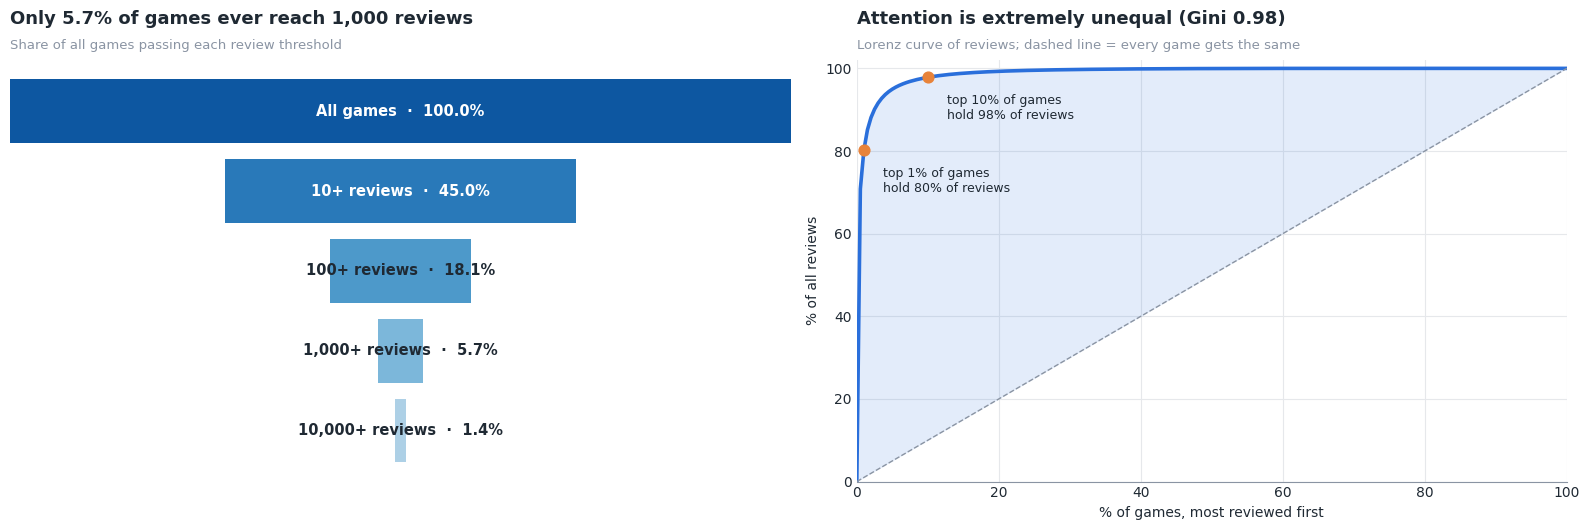

In [23]:
a = attention.iloc[0]
top1, top10 = a['top1_share'], a['top10_share']
funnel = pd.Series({'All games': 1.0, '10+ reviews': a['reviews_10'], '100+ reviews': a['reviews_100'],
                    '1,000+ reviews': a['reviews_1000'], '10,000+ reviews': a['reviews_10000']})

# Gini coefficient from the Lorenz curve: 0 = reviews spread evenly, 1 = one game has them all
lx = np.r_[0, lorenz['share_of_games']]
ly = np.r_[0, lorenz['share_of_reviews']]
gini = 2 * np.sum((lx[1:] - lx[:-1]) * (ly[1:] + ly[:-1]) / 2) - 1

fig, ax = plt.subplots(1, 2, figsize=(16, 5.4), gridspec_kw={'width_ratios': [1.1, 1]})

# Funnel: centred bars, width = share of all games
for i, (label, share) in enumerate(funnel.items()):
    y = len(funnel) - 1 - i
    ax[0].barh(y, share, left=(1 - share) / 2, height=0.8, color=plt.cm.Blues(0.85 - 0.13 * i))
    ax[0].text(0.5, y, f'{label}  ·  {pct(share, 1)}', ha='center', va='center', fontsize=10.5, fontweight='bold',
               color='white' if share > 0.35 else INK)
ax[0].set_xlim(0, 1)
ax[0].axis('off')
titles(ax[0], f'Only {pct(a["reviews_1000"], 1)} of games ever reach 1,000 reviews', 'Share of all games passing each review threshold')

# Lorenz curve
ax[1].fill_between(lx * 100, ly * 100, lx * 100, color=BLUE, alpha=0.13, lw=0)
ax[1].plot(lx * 100, ly * 100, color=BLUE, lw=2.6)
ax[1].plot([0, 100], [0, 100], color=MUTED, ls='--', lw=1)
for share_g, share_r in [(1, top1), (10, top10)]:
    ax[1].scatter(share_g, share_r * 100, color=ORANGE, s=60, zorder=3)
    ax[1].annotate(f'top {share_g}% of games\nhold {pct(share_r, 0)} of reviews', (share_g, share_r * 100),
                   xytext=(14, -30), textcoords='offset points', fontsize=9)
ax[1].set_xlim(0, 100)
ax[1].set_ylim(0, 102)
ax[1].set_xlabel('% of games, most reviewed first')
ax[1].set_ylabel('% of all reviews')
titles(ax[1], f'Attention is extremely unequal (Gini {gini:.2f})', 'Lorenz curve of reviews; dashed line = every game gets the same')
plt.tight_layout()
show(fig, 'fig04_attention_funnel_and_lorenz')

note(f'**Insight:** the top 1% of games hold **{pct(top1, 0)}** of all reviews and the top 10% hold **{pct(top10, 0)}** (Gini **{gini:.2f}**, '
     'where 1.0 would mean one game has every review). Success on Steam is winner-takes-most, so "above average" is a misleading target '
     'and a top-percentile definition fits better.')

### 🔗 4.3 Do the candidate success metrics agree?

<div style="background:#f4f0fa;border-left:5px solid #7b5ea7;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#7b5ea7">🧠 Why this step</b><br>"Successful" can mean commercial reach (owners, Peak CCU), quality (positive reviews) or engagement (playtime). If all metrics moved together one definition would be enough. <b>Spearman</b> rank correlation is used because every metric is heavily skewed, and the hexbin plot shows the raw relationship between reach and quality for every game.</div>

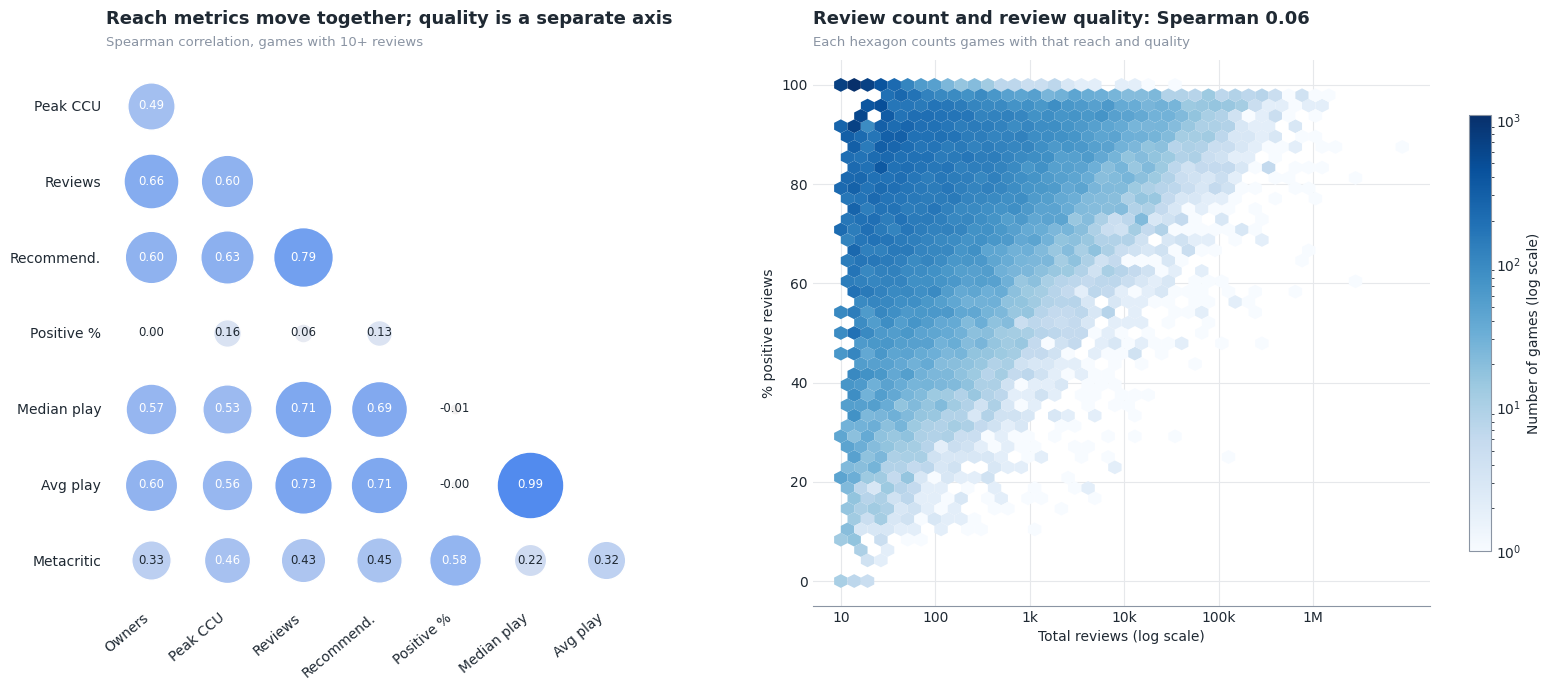

In [24]:
metrics = ['owners_mid', 'Peak CCU', 'total_reviews', 'Recommendations',
           'positive_ratio', 'Median playtime forever', 'Average playtime forever', 'Metacritic score']
short = ['Owners', 'Peak CCU', 'Reviews', 'Recommend.', 'Positive %', 'Median play', 'Avg play', 'Metacritic']
rated = df_clean[df_clean['total_reviews'] >= 10].copy()
rated['Metacritic score'] = rated['Metacritic score'].replace(0, np.nan)     # 0 means "no score" in this dataset
corr = rated[metrics].corr(method='spearman')

fig, ax = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={'width_ratios': [1.05, 1]})

# Dot matrix: circle size = strength, colour = direction (blue positive, orange negative)
cmap = sns.diverging_palette(28, 255, s=85, l=58, as_cmap=True)
k = len(metrics)
for i in range(1, k):
    for j in range(i):
        r = corr.iloc[i, j]
        ax[0].scatter(j, k - 1 - i, s=2300 * abs(r) + 40, color=cmap((r + 1) / 2), edgecolor='white', lw=1)
        ax[0].text(j, k - 1 - i, f'{r:.2f}', ha='center', va='center', fontsize=8.5,
                   color='white' if abs(r) > 0.45 else INK)
ax[0].set_xticks(range(k - 1))
ax[0].set_xticklabels(short[:-1], rotation=40, ha='right')
ax[0].set_yticks([k - 1 - i for i in range(1, k)])
ax[0].set_yticklabels(short[1:])
ax[0].set_xlim(-0.6, k - 1.4)
ax[0].set_ylim(-0.6, k - 1.4)
ax[0].set_aspect('equal')
ax[0].grid(False)
ax[0].spines['bottom'].set_visible(False)
titles(ax[0], 'Reach metrics move together; quality is a separate axis', 'Spearman correlation, games with 10+ reviews')

# Hexbin: reach against quality for every game
r_rq = corr.loc['total_reviews', 'positive_ratio']
hb = ax[1].hexbin(np.log10(rated['total_reviews']), rated['positive_ratio'] * 100, gridsize=42, cmap='Blues',
                  bins='log', mincnt=1, linewidths=0)
ax[1].set_xticks(range(1, 7))
ax[1].set_xticklabels(['10', '100', '1k', '10k', '100k', '1M'])
ax[1].set_xlabel('Total reviews (log scale)')
ax[1].set_ylabel('% positive reviews')
fig.colorbar(hb, ax=ax[1], shrink=0.8, label='Number of games (log scale)')
titles(ax[1], f'Review count and review quality: Spearman {r_rq:.2f}', 'Each hexagon counts games with that reach and quality')
plt.tight_layout()
show(fig, 'fig05_metric_correlations')

reach_corr = corr.loc['owners_mid', 'total_reviews']
quality_corr = corr.loc['owners_mid', 'positive_ratio']
note(f'**Insight:** owners and reviews correlate at **{reach_corr:.2f}**, but owners and positive ratio only at **{quality_corr:.2f}**. '
     'Reach and quality are different dimensions of success, so the notebook defines both, plus a strict "hit" that needs both.')

In [25]:
%%sql
-- Sanity check: the top 5 games by each reach metric should be names most players know
WITH long AS (
    SELECT 'owners_mid' AS metric, name, release_year, owners_mid AS metric_value FROM games
    UNION ALL
    SELECT 'peak_ccu', name, release_year, peak_ccu FROM games
    UNION ALL
    SELECT 'total_reviews', name, release_year, total_reviews FROM games
),
ranked AS (
    SELECT *, ROW_NUMBER() OVER (PARTITION BY metric ORDER BY metric_value DESC) AS pos
    FROM long
)
SELECT metric, pos, name, release_year, metric_value
FROM ranked
WHERE pos <= 5
ORDER BY metric, pos

,metric,pos,name,release_year,metric_value
0,owners_mid,1,Dota 2,2013,150000000
1,owners_mid,2,Counter-Strike 2,2012,150000000
2,owners_mid,3,Apex Legends™,2020,150000000
3,owners_mid,4,PUBG: BATTLEGROUNDS,2017,150000000
4,owners_mid,5,Call of Duty®,2022,75000000
5,peak_ccu,1,Counter-Strike 2,2012,1013936
6,peak_ccu,2,Dota 2,2013,623941
7,peak_ccu,3,PUBG: BATTLEGROUNDS,2017,314682
8,peak_ccu,4,Bongo Cat,2025,164168
9,peak_ccu,5,ELDEN RING NIGHTREIGN,2025,163599


<a id="s5"></a>
## 🏆 5. Defining success

Four definitions, each answering a different question:

| Label | Rule | Question |
|-------|------|----------|
| `commercial_success_year` | Top 10% by estimated owners **within its release year** | Did it reach many players, compared with games of the same age? |
| `quality_success` | At least 50 reviews and at least 80% positive | Do players who bought it like it? |
| `engagement_success` | Among games with 50+ reviews, top 10% by median playtime | Do players keep playing? |
| `hit` | Commercial and quality | Both at once, the strictest definition |

**Why "within its release year":** a game from 2012 has had a decade to gather owners and reviews, a game from 2023 has not.
A single global cutoff would label old games as successes and new games as failures regardless of quality.

**Note on ties:** owners come in wide buckets, so many games sit exactly on a year's cutoff and all of them count. That is why `commercial_success_year` covers more than 10% of games.

<div style="background:#f4f0fa;border-left:5px solid #7b5ea7;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#7b5ea7">🧠 Why this step</b><br>The whole analysis depends on this label, so it is defined several ways and checked for bias. A label that secretly measures "how old is the game" would make every later result about age, not success.</div>

In [26]:
# Parameters
MIN_REVIEWS = 50         # below this the positive ratio is too noisy to trust
MIN_POSITIVE = 0.80      # positive ratio that counts as "well liked"
TOP_PCT = 0.90           # top 10% = success
MIN_YEARS = 1            # games on sale for less than this have not had time to collect reviews
SPLIT_YEAR = 2021        # train on games released up to this year, test on later ones

# Keep games with a valid release date and owners estimate
base = df_clean[df_clean['release_year'].notna() & df_clean['owners_mid'].notna()].copy()

# Age: the newest release date in the data stands in for "today"
snapshot = base['Release date'].max()
base['years_since_release'] = ((snapshot - base['Release date']).dt.days / 365.25).clip(lower=0.25)
base['reviews_per_year'] = base['total_reviews'] / base['years_since_release']
base['owners_per_year'] = base['owners_mid'] / base['years_since_release']

# Commercial: raw (global cutoff) and age-adjusted (cutoff per release year)
global_cut = base['owners_mid'].quantile(TOP_PCT)
year_cut = base.groupby('release_year')['owners_mid'].transform(lambda s: s.quantile(TOP_PCT))
base['commercial_success'] = base['owners_mid'] >= max(global_cut, 1)
base['commercial_success_year'] = base['owners_mid'] >= year_cut.clip(lower=1)

# Quality and engagement
base['quality_success'] = (base['total_reviews'] >= MIN_REVIEWS) & (base['positive_ratio'] >= MIN_POSITIVE)
has_reviews = base['total_reviews'] >= MIN_REVIEWS
play_cut = base.loc[has_reviews, 'Median playtime forever'].quantile(TOP_PCT)
base['engagement_success'] = has_reviews & (base['Median playtime forever'] >= play_cut)

# Strict definition
base['hit'] = base['commercial_success_year'] & base['quality_success']

LABELS = ['commercial_success_year', 'quality_success', 'engagement_success', 'hit']

# Study set: games old enough for outcomes to have settled. Used for every test and the model.
study = base[base['years_since_release'] >= MIN_YEARS].copy()

print(f'All games with date and owners: {len(base):,}    Study set (on sale {MIN_YEARS}+ year): {len(study):,}')
print(f'Global owners cutoff {global_cut:,.0f}    Median playtime cutoff (50+ reviews) {play_cut:,.0f} min')
(study[LABELS].mean() * 100).round(2).to_frame('% of study games')

All games with date and owners: 125,854    Study set (on sale 1+ year): 120,629
Global owners cutoff 75,000    Median playtime cutoff (50+ reviews) 658 min


,% of study games
commercial_success_year,22.860
quality_success,13.980
engagement_success,2.540
hit,5.930


In [27]:
# Add the labels to the database. All games with a date and owners; in_study marks the games used in tests and models.
labels_tbl = base[['AppID', 'commercial_success'] + LABELS].rename(columns={'AppID': 'app_id'})
labels_tbl['in_study'] = base['years_since_release'] >= MIN_YEARS
save_table('labels', labels_tbl)

In [28]:
%%sql by_year <<
-- Share of games labelled successful per release year: one global owners cutoff vs a cutoff within each year
SELECT g.release_year,
       AVG(CAST(l.commercial_success AS DOUBLE)) * 100      AS global_cutoff,
       AVG(CAST(l.commercial_success_year AS DOUBLE)) * 100 AS within_year_cutoff,
       COUNT(*)                                             AS n_games
FROM labels AS l
JOIN games AS g USING (app_id)
WHERE g.release_year >= 2008
GROUP BY g.release_year
ORDER BY g.release_year

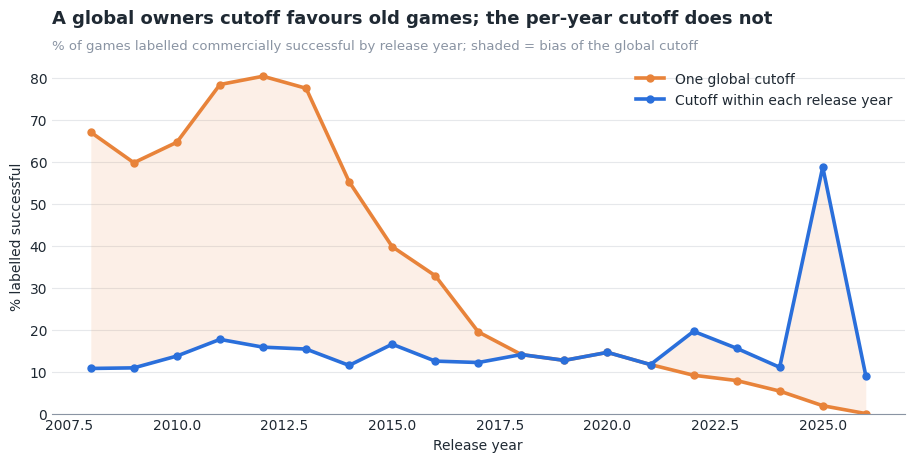

'/kaggle/working/figures/fig06_age_bias_of_success_label.png'

In [29]:
# The age problem, visible: a global cutoff turns "success" into "old game"
fig, ax = plt.subplots(figsize=(11, 4.6))
x = by_year['release_year']
ax.fill_between(x, by_year['global_cutoff'], by_year['within_year_cutoff'], color=ORANGE, alpha=0.12, lw=0)
ax.plot(x, by_year['global_cutoff'], color=ORANGE, lw=2.6, marker='o', ms=5, label='One global cutoff')
ax.plot(x, by_year['within_year_cutoff'], color=BLUE, lw=2.6, marker='o', ms=5, label='Cutoff within each release year')
ax.set_ylim(0, None)
ax.set_ylabel('% labelled successful')
ax.set_xlabel('Release year')
ax.legend(loc='upper right')
ax.grid(axis='x', visible=False)
titles(ax, 'A global owners cutoff favours old games; the per-year cutoff does not',
       '% of games labelled commercially successful by release year; shaded = bias of the global cutoff')
show(fig, 'fig06_age_bias_of_success_label')

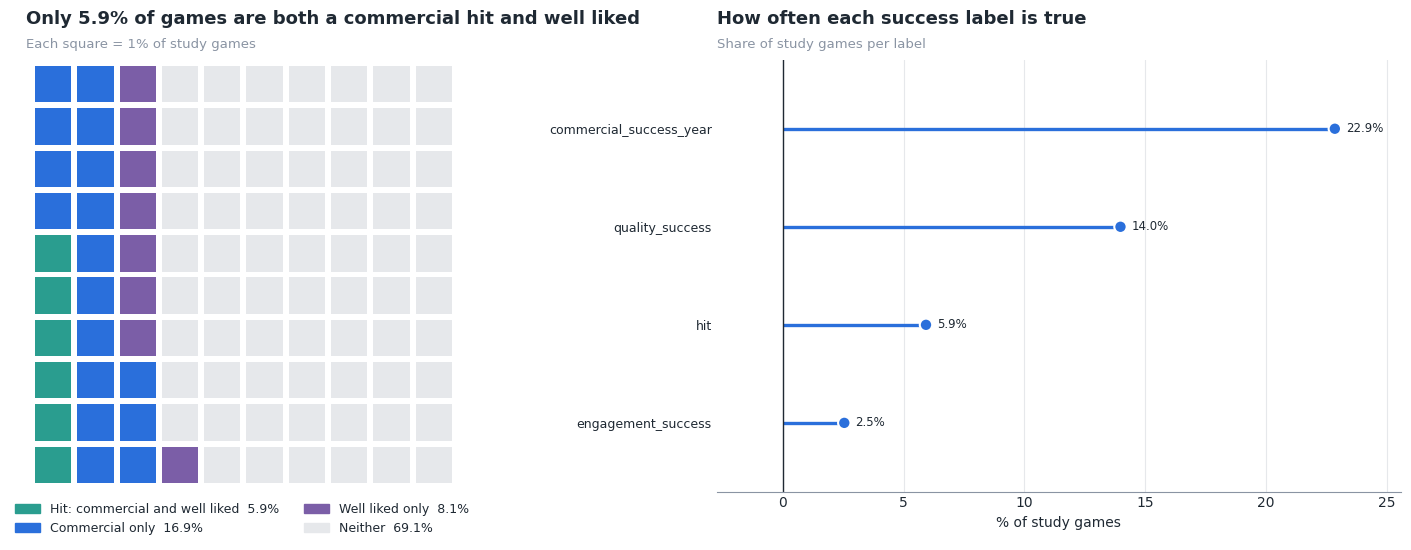

In [30]:
# How do commercial and quality success overlap? Waffle chart: each square = 1% of study games
both = (study['commercial_success_year'] & study['quality_success']).mean()
comm_only = (study['commercial_success_year'] & ~study['quality_success']).mean()
qual_only = (~study['commercial_success_year'] & study['quality_success']).mean()
shares = {'Hit: commercial and well liked': both, 'Commercial only': comm_only,
          'Well liked only': qual_only, 'Neither': 1 - both - comm_only - qual_only}
colors = [TEAL, BLUE, PURPLE, GRID]

fig, ax = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={'width_ratios': [1, 1.1]})
waffle(ax[0], shares, colors)
ax[0].legend([Rectangle((0, 0), 1, 1, color=c) for c in colors], [f'{k}  {pct(v, 1)}' for k, v in shares.items()],
             loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=2, fontsize=9)
titles(ax[0], f'Only {pct(both, 1)} of games are both a commercial hit and well liked', 'Each square = 1% of study games')

rates = (study[LABELS].mean() * 100).sort_values()
lollipop(ax[1], rates, center=0, fmt='{:.1f}%')
ax[1].set_xlabel('% of study games')
titles(ax[1], 'How often each success label is true', 'Share of study games per label')
plt.tight_layout()
show(fig, 'fig07_label_overlap_waffle')

p_quality_given_comm = study.loc[study['commercial_success_year'], 'quality_success'].mean()
note(f'**Insight:** only **{pct(p_quality_given_comm, 0)}** of commercial hits are also well liked ({pct(study["quality_success"].mean(), 0)} of all games are). '
     'Reaching many players and satisfying them are related but not the same thing, so `hit` is a much rarer label than either part.')

<a id="s6"></a>
## 🧪 6. Testing indicators

Each launch-time feature is compared with one target at a time. Change `TARGET` and rerun the section to compare definitions.

**Three tools, each answering a different question:**
1. **AUC** ranks numeric features by how well they separate successful from other games (0.5 = no signal).
2. **Success rate with a 95% interval** shows the shape of the relationship and how much to trust it.
3. **Lift** (rate of a group divided by the overall rate) compares genres and tags on one scale: 1.0 = average.

All of these show association, not cause. A high-quality game may add languages *because* it sells.

<div style="background:#f4f0fa;border-left:5px solid #7b5ea7;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#7b5ea7">🧠 Why this step</b><br>A model can say *that* launch facts predict success, but not *which* facts or *how*. Testing features one at a time, with effect sizes and confidence intervals, gives findings a reader can check and an interviewer can question.</div>

In [31]:
# Parameters
TARGET = 'hit'          # one of: commercial_success_year, quality_success, engagement_success, hit
MIN_GROUP = 300         # smallest group size shown in genre / tag tables

overall = study[TARGET].mean()
print(f'Target: {TARGET}    overall rate {pct(overall)}    positives {study[TARGET].sum():,} of {len(study):,}')

Target: hit    overall rate 5.9%    positives 7,150 of 120,629


### 🎯 6.1 Indicator scorecard
AUC per numeric launch-time feature for the chosen `TARGET`. Right of 0.5 = higher in successful games, left = lower. Appendix B compares all four labels.

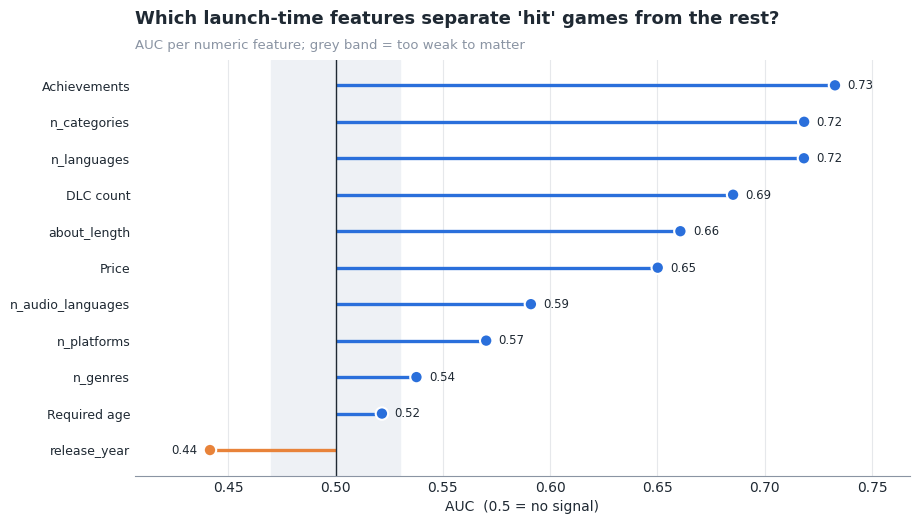

In [32]:
indicator_features = ['Price', 'n_languages', 'n_audio_languages', 'Achievements', 'DLC count', 'n_genres',
                      'n_categories', 'about_length', 'Required age', 'n_platforms', 'release_year']

# AUC for every feature against every label (the full table is reused in Appendix B)
score = pd.DataFrame({
    lab: {f: auc_score(study.loc[study[lab], f], study.loc[~study[lab], f]) for f in indicator_features}
    for lab in LABELS
})
score = score.loc[(score - 0.5).abs().max(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(10, 5.4))
ax.axvspan(0.47, 0.53, color=PALE, zorder=0)
lollipop(ax, score[TARGET].sort_values(), center=0.5)
ax.set_xlabel('AUC  (0.5 = no signal)')
titles(ax, f"Which launch-time features separate '{TARGET}' games from the rest?",
       'AUC per numeric feature; grey band = too weak to matter')
show(fig, 'fig08_indicator_auc')

strongest = (score[TARGET] - 0.5).abs().sort_values(ascending=False).head(3).index
note('**Insight:** for `' + TARGET + '` the strongest numeric indicators are ' +
     ', '.join(f'**{f}** (AUC {score.loc[f, TARGET]:.2f})' for f in strongest) +
     '. An AUC of 0.60 means a random successful game ranks above a random other game 60% of the time, '
     'so values near 0.5 are weak even when a test calls them "significant" on 100k+ games.')

### 📉 6.2 Shape of the relationship
Success rate per bucket. The shaded ribbon is the 95% interval: where ribbons of two buckets overlap, the difference between them is not reliable.

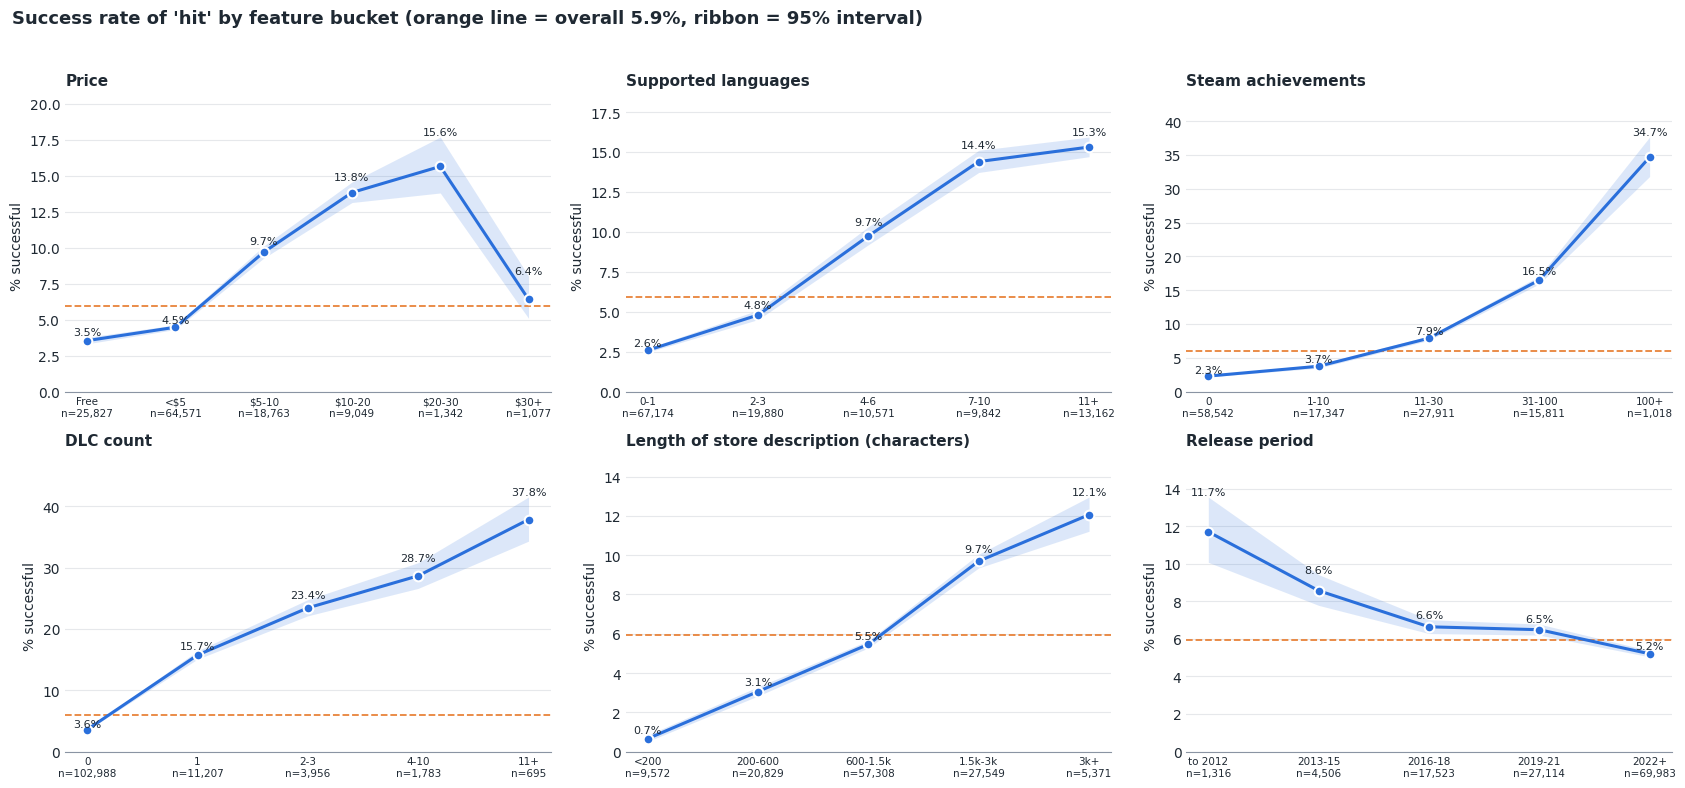

'/kaggle/working/figures/fig09_success_rate_by_bucket.png'

In [33]:
fig, ax = plt.subplots(2, 3, figsize=(17, 8))
rate_plot(ax[0, 0], study, 'Price', TARGET, [-1, 0, 5, 10, 20, 30, 1000], ['Free', '<$5', '$5-10', '$10-20', '$20-30', '$30+'], 'Price')
rate_plot(ax[0, 1], study, 'n_languages', TARGET, [-1, 1, 3, 6, 10, 200], ['0-1', '2-3', '4-6', '7-10', '11+'], 'Supported languages')
rate_plot(ax[0, 2], study, 'Achievements', TARGET, [-1, 0, 10, 30, 100, 100000], ['0', '1-10', '11-30', '31-100', '100+'], 'Steam achievements')
rate_plot(ax[1, 0], study, 'DLC count', TARGET, [-1, 0, 1, 3, 10, 100000], ['0', '1', '2-3', '4-10', '11+'], 'DLC count')
rate_plot(ax[1, 1], study, 'about_length', TARGET, [-1, 200, 600, 1500, 3000, 1e6], ['<200', '200-600', '600-1.5k', '1.5k-3k', '3k+'],
          'Length of store description (characters)')
rate_plot(ax[1, 2], study, 'release_year', TARGET, [2007, 2012, 2015, 2018, 2021, 2030], ['to 2012', '2013-15', '2016-18', '2019-21', '2022+'],
          'Release period')
fig.suptitle(f"Success rate of '{TARGET}' by feature bucket (orange line = overall {pct(overall)}, ribbon = 95% interval)", x=0.01, ha='left',
             fontsize=13, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.96])
show(fig, 'fig09_success_rate_by_bucket')

### 🔀 6.3 Yes / no features
A **dumbbell chart**: orange = games without the feature, blue = with it, the grey bar is the gap. Thin whiskers are 95% intervals.

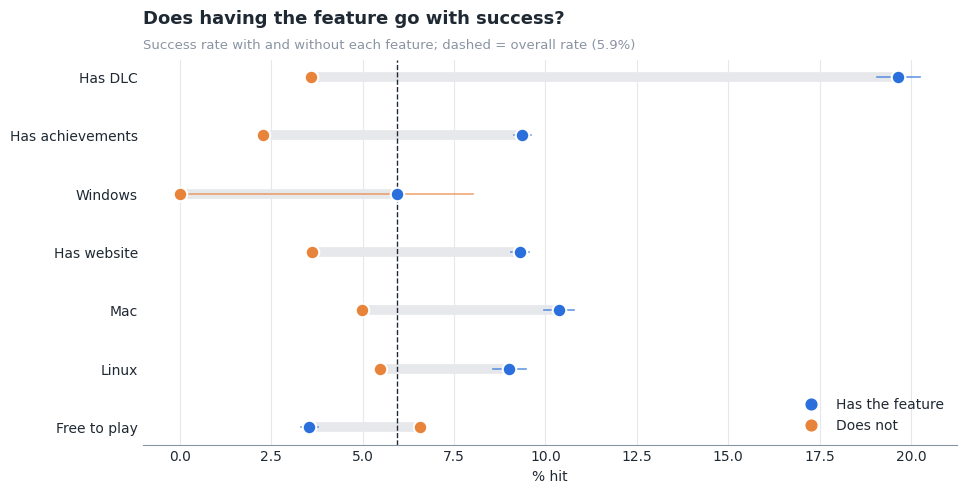

In [34]:
flags = {'Windows': 'Windows', 'Mac': 'Mac', 'Linux': 'Linux', 'is_free': 'Free to play', 'has_website': 'Has website',
         'has_achievements': 'Has achievements', 'has_dlc': 'Has DLC'}

rows = []
for col, name in flags.items():
    for val in (True, False):
        s = study.loc[study[col] == val, TARGET]
        if len(s) < 30:
            continue
        lo, hi = wilson(s.sum(), len(s))
        rows.append({'feature': name, 'present': val, 'rate': s.mean(), 'lo': float(lo), 'hi': float(hi), 'n': len(s)})
flag_df = pd.DataFrame(rows)

rate_w = flag_df.pivot(index='feature', columns='present', values='rate').reindex(columns=[False, True])
order = (rate_w[True] - rate_w[False]).fillna(0).sort_values().index

fig, ax = plt.subplots(figsize=(10.5, 5))
for yi, feat in enumerate(order):
    without, with_ = rate_w.loc[feat, False], rate_w.loc[feat, True]
    if pd.notna(without) and pd.notna(with_):
        ax.plot([without * 100, with_ * 100], [yi, yi], color=GRID, lw=7, solid_capstyle='round', zorder=1)
    for _, r in flag_df[flag_df['feature'] == feat].iterrows():
        color = BLUE if r['present'] else ORANGE
        ax.plot([r['lo'] * 100, r['hi'] * 100], [yi, yi], color=color, lw=1.2, alpha=0.7, zorder=2)
        ax.scatter(r['rate'] * 100, yi, color=color, s=95, zorder=3, edgecolor='white', linewidth=1.5)
ax.axvline(overall * 100, color=INK, lw=1, ls='--')
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
ax.set_xlabel(f'% {TARGET}')
ax.scatter([], [], color=BLUE, s=60, label='Has the feature')
ax.scatter([], [], color=ORANGE, s=60, label='Does not')
ax.legend(loc='lower right')
ax.grid(axis='y', visible=False)
titles(ax, 'Does having the feature go with success?', f'Success rate with and without each feature; dashed = overall rate ({pct(overall)})')
show(fig, 'fig10_yes_no_dumbbell')

# Insight: largest gap in percentage points, only where both groups have at least MIN_GROUP games
big = flag_df[flag_df['n'] >= MIN_GROUP]
piv = big.pivot(index='feature', columns='present', values='rate').dropna()
if len(piv):
    piv['gap'] = piv[True] - piv[False]
    top = piv['gap'].abs().idxmax()
    note(f'**Insight:** the largest yes/no gap is **{top}**: {pct(piv.loc[top, True])} with it vs {pct(piv.loc[top, False])} without '
         f'({piv.loc[top, "gap"] * 100:+.1f} points). Groups under {MIN_GROUP} games are left out of this comparison.')

### 🏷️ 6.4 Genres and tags
Lift = success rate of games with the label / overall rate. Only labels with at least `MIN_GROUP` games are shown, because rates from small groups swing wildly.
Tags are voted by players *after* release, so tags describe popular games as much as they predict them. Use them to understand, not to predict.

The query computes lift for **every genre and tag under all four success labels** in one pass: the four label columns are turned into rows (`labels_long`), so a single `GROUP BY` covers them all. Appendix B reuses the result.

Shown as a **forest plot** on a log scale, so 2x and 0.5x are the same distance from average.

In [35]:
%%sql lift_all <<
WITH labels_long AS (                   -- one row per game and label
    SELECT app_id, 'commercial_success_year' AS label, CAST(commercial_success_year AS INTEGER) AS success
    FROM labels WHERE in_study
    UNION ALL
    SELECT app_id, 'quality_success', CAST(quality_success AS INTEGER) FROM labels WHERE in_study
    UNION ALL
    SELECT app_id, 'engagement_success', CAST(engagement_success AS INTEGER) FROM labels WHERE in_study
    UNION ALL
    SELECT app_id, 'hit', CAST(hit AS INTEGER) FROM labels WHERE in_study
),
overall_rates AS (                      -- base rate per label
    SELECT label, AVG(CAST(success AS DOUBLE)) AS overall
    FROM labels_long
    GROUP BY label
),
attributes AS (                         -- genres and tags in one shape
    SELECT app_id, 'genre' AS kind, genre AS item FROM game_genres
    UNION ALL
    SELECT app_id, 'tag', tag FROM game_tags
)
SELECT a.kind,
       a.item,
       s.label,
       SUM(s.success)                                  AS k,
       COUNT(*)                                        AS n,
       AVG(CAST(s.success AS DOUBLE))                  AS rate,
       AVG(CAST(s.success AS DOUBLE)) / MAX(o.overall) AS lift,
       MAX(o.overall)                                  AS overall
FROM attributes AS a
JOIN labels_long AS s USING (app_id)
JOIN overall_rates AS o USING (label)
GROUP BY a.kind, a.item, s.label
HAVING COUNT(*) >= {{MIN_GROUP}}

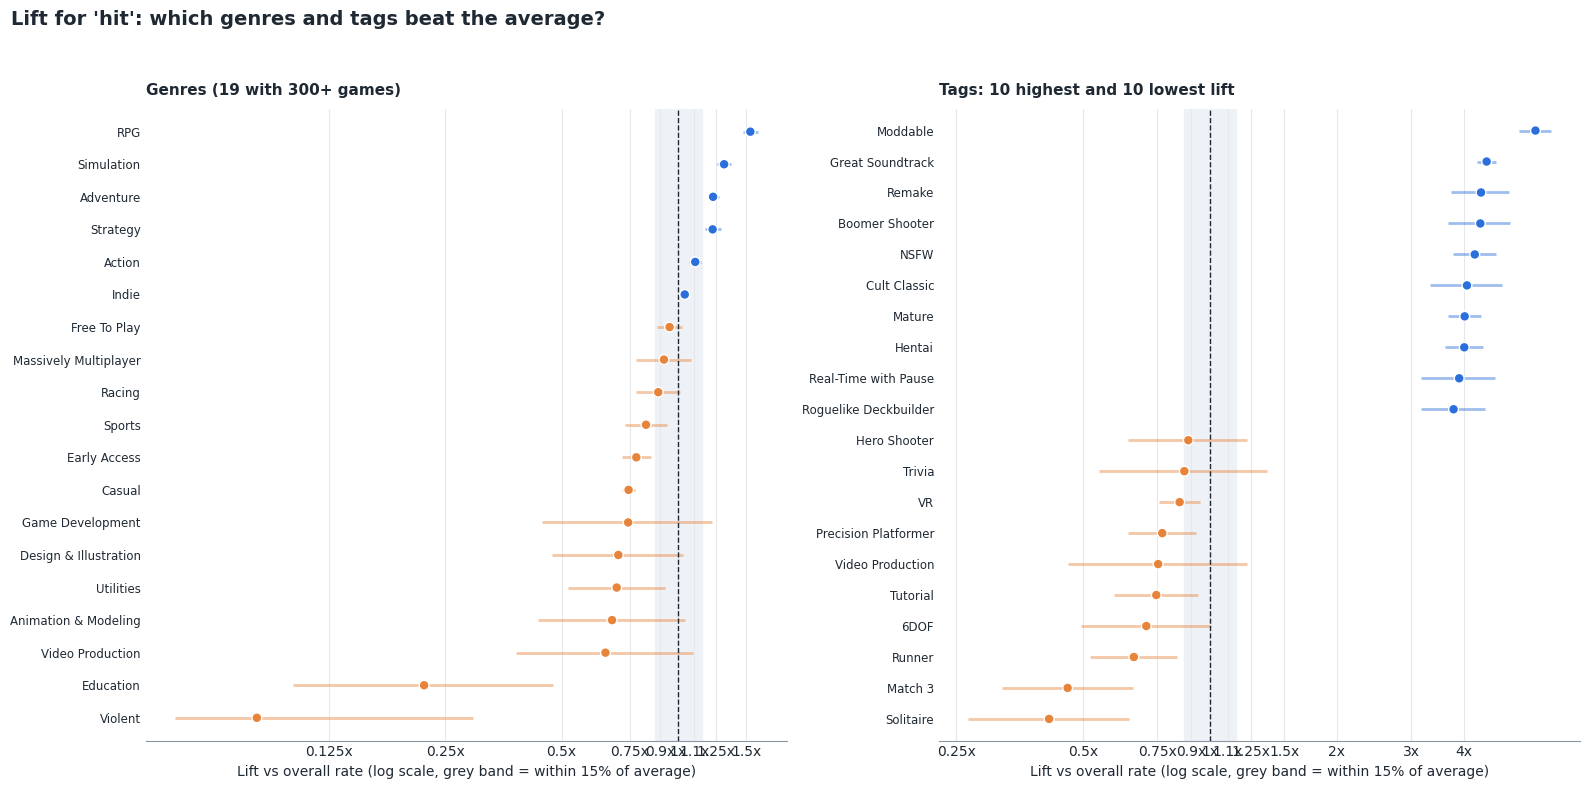

In [36]:
def lift_table(kind, target):
    """Rows of lift_all for one kind (genre / tag) and one label, with a 95% interval, sorted by lift."""
    g = lift_all[(lift_all['kind'] == kind) & (lift_all['label'] == target)].set_index('item').copy()
    g['lo'], g['hi'] = wilson(g['k'], g['n'])
    return g.sort_values('lift')


genre_fx = lift_table('genre', TARGET)
tag_fx = lift_table('tag', TARGET)
tag_show = pd.concat([tag_fx.head(10), tag_fx.tail(10)]) if len(tag_fx) > 20 else tag_fx

fig, ax = plt.subplots(1, 2, figsize=(16, max(5.5, 0.3 * max(len(genre_fx), len(tag_show)) + 2)))
lift_plot(ax[0], genre_fx, f'Genres ({len(genre_fx)} with {MIN_GROUP}+ games)')
lift_plot(ax[1], tag_show, 'Tags: 10 highest and 10 lowest lift')
fig.suptitle(f"Lift for '{TARGET}': which genres and tags beat the average?", x=0.01, ha='left', fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.95])
show(fig, 'fig11_genre_tag_lift')

best, worst = genre_fx.index[-1], genre_fx.index[0]
note(f'**Insight:** among genres, **{best}** has the highest lift ({genre_fx.loc[best, "lift"]:.1f}x, {pct(genre_fx.loc[best, "rate"])}) '
     f'and **{worst}** the lowest ({genre_fx.loc[worst, "lift"]:.1f}x, {pct(genre_fx.loc[worst, "rate"])}). '
     'Genre labels overlap (a game has several), so lifts are not additive.')

<a id="s7"></a>
## 🤖 7. Modelling

**Question:** using only what is known at (or near) launch, how well can a model separate games that become successful from those that do not?

Rules that keep the result honest:
- **No outcome columns as features.** Owners, Peak CCU, reviews, Positive/Negative, Recommendations, playtime, Metacritic and User score define or follow success. Including them would give a perfect score and teach nothing.
- **No `n_tags`.** Tags are voted by players after release.
- **Time-based split.** Train on games up to `SPLIT_YEAR`, test on later ones. A random split would let the model learn from the future.
- **Only games old enough** for outcomes to settle (`MIN_YEARS`).
- `Discount` is left out because it changes over time. `DLC count`, `Achievements` and trading cards can grow after launch, so treat their importance with some caution.

<div style="background:#f4f0fa;border-left:5px solid #7b5ea7;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#7b5ea7">🧠 Why this step</b><br>Single-feature tests ignore that features overlap (games with many languages also tend to have achievements). A model combines them and answers the practical question: given only what a studio knows at launch, how well can success be ranked? Gradient boosting is used because it handles skewed features and interactions without manual transformations.</div>

In [37]:
# Feature matrix
num_features = ['Price', 'is_free', 'Required age', 'DLC count', 'Achievements', 'n_languages', 'n_audio_languages',
                'n_genres', 'n_categories', 'n_platforms', 'about_length', 'has_website', 'Windows', 'Mac', 'Linux']

genre_counts = study['Genres_list'].explode().value_counts()
top_genres = list(genre_counts[genre_counts >= 500].index)
top_set = set(top_genres)

from sklearn.preprocessing import MultiLabelBinarizer
mlb = MultiLabelBinarizer(classes=top_genres)
genre_dummies = pd.DataFrame(
    mlb.fit_transform(study['Genres_list'].map(lambda g: [x for x in g if x in top_set])),
    index=study.index, columns=['genre_' + g for g in top_genres])

X = pd.concat([study[num_features].astype(float), genre_dummies], axis=1)

train = (study['release_year'] <= SPLIT_YEAR).to_numpy()
test = ~train
print(f'Features: {X.shape[1]}  ({len(num_features)} numeric + {len(top_genres)} genre flags)')
print(f'Train: {train.sum():,} games (released up to {SPLIT_YEAR})    Test: {test.sum():,} games (released later)')

Features: 29  (15 numeric + 14 genre flags)
Train: 50,646 games (released up to 2021)    Test: 69,983 games (released later)


In [38]:
# The success rate drifts over time, so the test base rate differs from the training base rate
drift = pd.DataFrame({
    'train rate %': study.loc[train, LABELS].mean() * 100,
    'test rate %': study.loc[test, LABELS].mean() * 100,
}).round(2)
drift['test / train'] = (drift['test rate %'] / drift['train rate %']).round(2)
drift

,train rate %,test rate %,test / train
commercial_success_year,13.190,29.850,2.260
quality_success,20.600,9.190,0.450
engagement_success,3.450,1.890,0.550
hit,6.920,5.210,0.750


<div style="background:#eef4ff;border-left:5px solid #2a6fdb;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#2a6fdb">📌 Note</b><br>A lower test rate does not break the model, but it changes how to read precision. AUC compares rankings and is largely unaffected by the base rate; average precision is not, so compare it to the test base rate, not to the training one.</div>

In [39]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score


def fit_eval(cols, target, frame=None):
    """Fit on the training years, score on the test years. Returns model, test probabilities, metrics."""
    frame = X if frame is None else frame
    y = study[target].astype(int)
    m = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.06, max_iter=200, min_samples_leaf=50,
                                       l2_regularization=1.0, early_stopping=False, random_state=42)
    m.fit(frame.loc[train, cols], y[train])
    p = m.predict_proba(frame.loc[test, cols])[:, 1]
    return m, p, {'auc': roc_auc_score(y[test], p), 'avg_precision': average_precision_score(y[test], p),
                  'test_base_rate': y[test].mean()}


fits = {lab: fit_eval(list(X.columns), lab) for lab in LABELS}       # (model, test probabilities, metrics)
results = pd.DataFrame({lab: fits[lab][2] for lab in LABELS}).T
results['precision_lift'] = results['avg_precision'] / results['test_base_rate']
results

,auc,avg_precision,test_base_rate,precision_lift
commercial_success_year,0.633,0.428,0.299,1.435
quality_success,0.782,0.299,0.092,3.251
engagement_success,0.907,0.244,0.019,12.949
hit,0.805,0.235,0.052,4.523


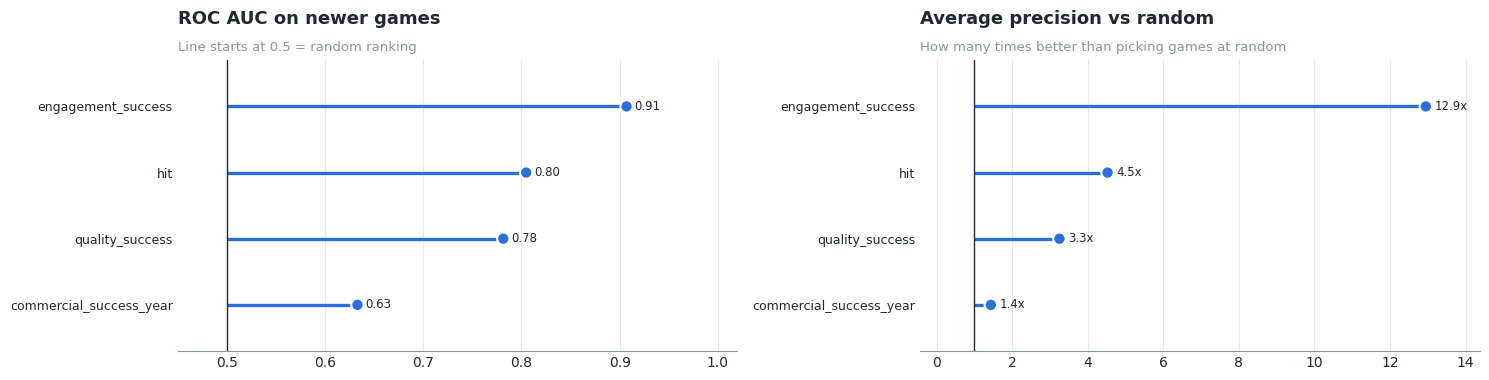

In [40]:
fig, ax = plt.subplots(1, 2, figsize=(15, 3.9))
lollipop(ax[0], results['auc'].sort_values(), center=0.5)
ax[0].set_xlim(0.45, 1.02)
titles(ax[0], 'ROC AUC on newer games', 'Line starts at 0.5 = random ranking')
lollipop(ax[1], results['precision_lift'].sort_values(), center=1, fmt='{:.1f}x')
titles(ax[1], 'Average precision vs random', 'How many times better than picking games at random')
plt.tight_layout()
show(fig, 'fig12_model_scores_per_label')

best_lab = results['auc'].idxmax()
note(f'**Insight:** launch-time features predict **{best_lab}** best (AUC {results.loc[best_lab, "auc"]:.2f}) and '
     f'**{results["auc"].idxmin()}** worst (AUC {results["auc"].min():.2f}). '
     'An AUC well above 0.5 means launch-time facts carry real signal, but the gap to 1.0 is what marketing, quality and luck explain.')

### 🔬 7.1 Focus model: `TARGET`

<div style="background:#f4f0fa;border-left:5px solid #7b5ea7;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#7b5ea7">🧠 Why this step</b><br>AUC is abstract. Two pictures make it concrete: the <b>cumulative gains curve</b> answers "if a publisher only looks at the top X% of the model's picks, what share of the real successes do they catch?", and the <b>calibration curve</b> checks whether a predicted 20% chance really means 20%. Then <b>ablation</b>, <b>permutation importance</b> and <b>SHAP</b> show what the model relies on.</div>

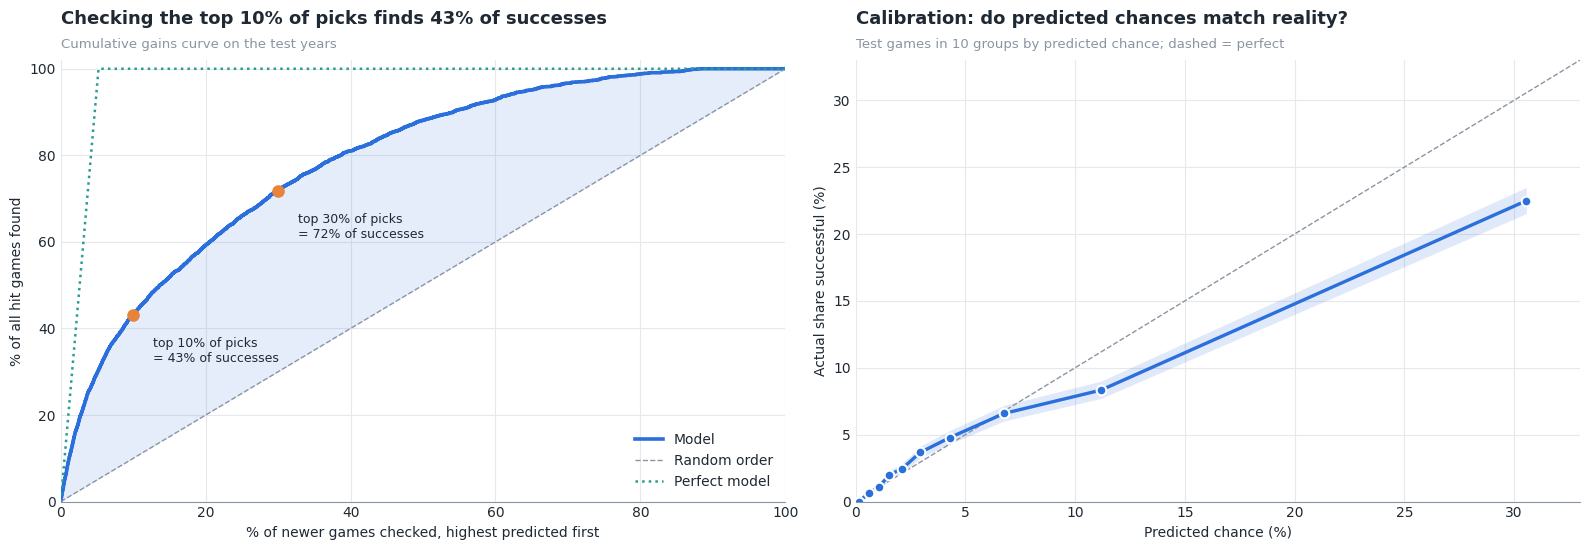

In [41]:
model, proba, main = fits[TARGET]
y_test = study.loc[test, TARGET].astype(int).to_numpy()

# Cumulative gains: sort test games by predicted score, track the share of all successes found so far
order_p = np.argsort(-proba)
found = np.cumsum(y_test[order_p]) / max(y_test.sum(), 1)
looked = np.arange(1, len(order_p) + 1) / len(order_p)
capture_top = found[int(np.ceil(0.1 * len(found))) - 1]
capture_top30 = found[int(np.ceil(0.3 * len(found))) - 1]

# Calibration: 10 equal-size groups by predicted chance, predicted vs actual rate
cal = pd.DataFrame({'p': proba, 'y': y_test})
cal['bin'] = pd.qcut(cal['p'].rank(method='first'), 10, labels=False)
cal = cal.groupby('bin').agg(pred=('p', 'mean'), obs=('y', 'mean'), n=('y', 'size'))
cal['lo'], cal['hi'] = wilson(cal['obs'] * cal['n'], cal['n'])

fig, ax = plt.subplots(1, 2, figsize=(16, 5.6))

ax[0].fill_between(looked * 100, found * 100, looked * 100, color=BLUE, alpha=0.12, lw=0)
ax[0].plot(looked * 100, found * 100, color=BLUE, lw=2.6, label='Model')
ax[0].plot([0, 100], [0, 100], color=MUTED, ls='--', lw=1, label='Random order')
ax[0].plot([0, y_test.mean() * 100, 100], [0, 100, 100], color=TEAL, ls=':', lw=1.8, label='Perfect model')
for share_g, share_f in [(10, capture_top), (30, capture_top30)]:
    ax[0].scatter(share_g, share_f * 100, color=ORANGE, s=65, zorder=3)
    ax[0].annotate(f'top {share_g}% of picks\n= {pct(share_f, 0)} of successes', (share_g, share_f * 100),
                   xytext=(14, -34), textcoords='offset points', fontsize=9)
ax[0].set_xlim(0, 100)
ax[0].set_ylim(0, 102)
ax[0].set_xlabel('% of newer games checked, highest predicted first')
ax[0].set_ylabel(f'% of all {TARGET} games found')
ax[0].legend(loc='lower right')
titles(ax[0], f'Checking the top 10% of picks finds {pct(capture_top, 0)} of successes', 'Cumulative gains curve on the test years')

lim = max(cal['pred'].max(), cal['hi'].max()) * 100 * 1.08
ax[1].plot([0, lim], [0, lim], color=MUTED, ls='--', lw=1)
ax[1].fill_between(cal['pred'] * 100, cal['lo'] * 100, cal['hi'] * 100, color=BLUE, alpha=0.15, lw=0)
ax[1].plot(cal['pred'] * 100, cal['obs'] * 100, color=BLUE, lw=2.4, marker='o', ms=7, mec='white', mew=1.5)
ax[1].set_xlim(0, lim)
ax[1].set_ylim(0, lim)
ax[1].set_xlabel('Predicted chance (%)')
ax[1].set_ylabel('Actual share successful (%)')
titles(ax[1], 'Calibration: do predicted chances match reality?', 'Test games in 10 groups by predicted chance; dashed = perfect')
plt.tight_layout()
show(fig, 'fig13_gains_and_calibration')

note(f'**Insight:** ranking newer games by the model, the top 10% contain **{pct(capture_top, 0)}** of all `{TARGET}` games and the top 30% '
     f'contain **{pct(capture_top30, 0)}** (test AUC {main["auc"]:.2f}). On average the model predicts **{pct(proba.mean())}** while '
     f'**{pct(y_test.mean())}** of test games succeed: the base rate drifted between the training and test years, so the ranking is useful '
     'but the raw probabilities need recalibrating before being read as chances.')

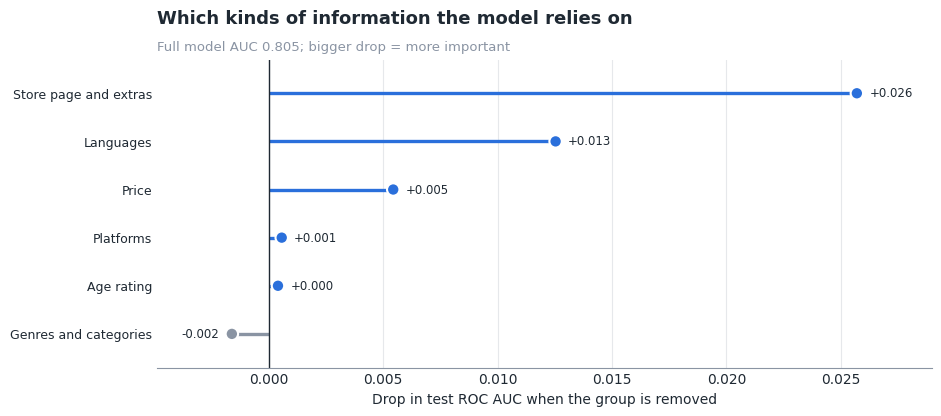

'/kaggle/working/figures/fig14_feature_group_ablation.png'

In [42]:
# Feature-group ablation: refit without a group and see how much AUC drops. Bigger drop = group matters more.
groups = {
    'Price': ['Price', 'is_free'],
    'Languages': ['n_languages', 'n_audio_languages'],
    'Genres and categories': ['n_genres', 'n_categories'] + list(genre_dummies.columns),
    'Store page and extras': ['about_length', 'has_website', 'DLC count', 'Achievements'],
    'Platforms': ['n_platforms', 'Windows', 'Mac', 'Linux'],
    'Age rating': ['Required age'],
}
y_all = study[TARGET].astype(int)
ablate = {}
for name, cols in groups.items():
    keep_cols = [c for c in X.columns if c not in cols]
    _, p_, _ = fit_eval(keep_cols, TARGET)
    ablate[name] = main['auc'] - roc_auc_score(y_all[test], p_)
ablate = pd.Series(ablate).sort_values()

fig, ax = plt.subplots(figsize=(10, 4))
lollipop(ax, ablate, center=0, fmt='{:+.3f}', colors=[BLUE if v > 0 else MUTED for v in ablate])
ax.set_xlabel('Drop in test ROC AUC when the group is removed')
titles(ax, f'Which kinds of information the model relies on', f'Full model AUC {main["auc"]:.3f}; bigger drop = more important')
show(fig, 'fig14_feature_group_ablation')

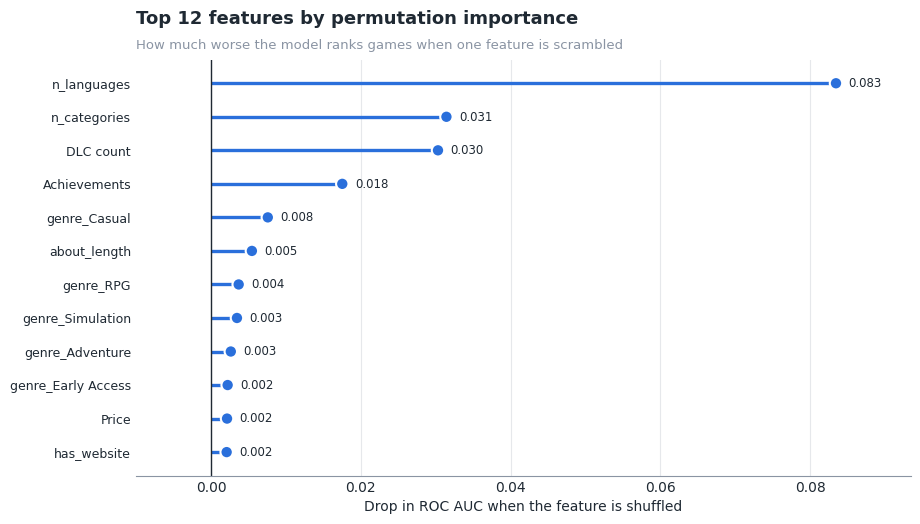

'/kaggle/working/figures/fig15_permutation_importance.png'

In [43]:
# Single-feature importance: shuffle one feature at a time on a test sample and measure the AUC drop
from sklearn.inspection import permutation_importance

sample = np.random.RandomState(42).choice(np.where(test)[0], size=min(15_000, test.sum()), replace=False)
Xs, ys = X.iloc[sample], y_all.iloc[sample]
perm = permutation_importance(model, Xs, ys, scoring='roc_auc', n_repeats=3, random_state=42)
importance = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 5.4))
lollipop(ax, importance.head(12)[::-1], center=0, fmt='{:.3f}')
ax.set_xlabel('Drop in ROC AUC when the feature is shuffled')
titles(ax, 'Top 12 features by permutation importance', 'How much worse the model ranks games when one feature is scrambled')
show(fig, 'fig15_permutation_importance')

<div style="background:#eef4ff;border-left:5px solid #2a6fdb;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#2a6fdb">📌 Note</b><br><b>SHAP</b> goes one step further than importance: every dot is one game, its position shows how much a feature pushed that game's prediction up or down, and its colour shows whether the feature value was high (red) or low (blue). It reveals direction and spread, not just size. The <code>shap</code> package is preinstalled on Kaggle; elsewhere <code>pip install shap</code>.</div>

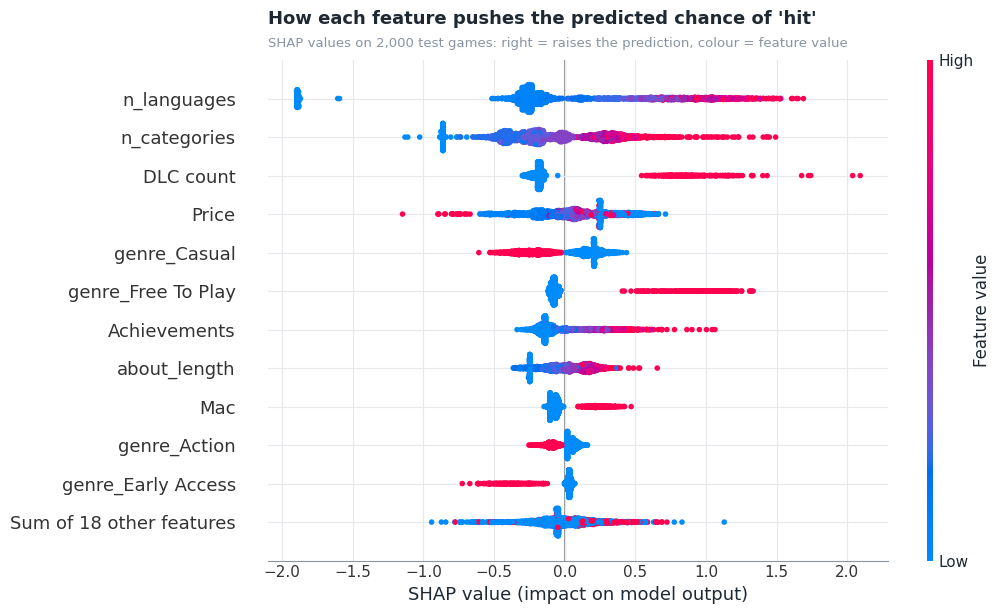

In [44]:
# SHAP beeswarm for the focus model, on 2,000 test games (skipped with a message if shap is not available)
try:
    import shap

    idx = np.random.RandomState(42).choice(np.where(test)[0], size=min(2000, test.sum()), replace=False)
    sv = shap.TreeExplainer(model)(X.iloc[idx])
    if sv.values.ndim == 3:                 # some versions return one set of values per class
        sv = sv[:, :, 1]
    shap.plots.beeswarm(sv, max_display=12, show=False)
    fig = plt.gcf()
    fig.set_size_inches(10, 6.5)
    titles(plt.gca(), f"How each feature pushes the predicted chance of '{TARGET}'",
           'SHAP values on 2,000 test games: right = raises the prediction, colour = feature value')
    show(fig, 'fig16_shap_beeswarm')
except Exception as e:
    callout(f'SHAP chart skipped ({type(e).__name__}: {e}). Install it with `pip install shap` to see it.', 'caution')

<a id="s8"></a>
## 📌 8. Findings and limits

<div style="background:#f4f0fa;border-left:5px solid #7b5ea7;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#7b5ea7">🧠 Why this step</b><br>A reader who skips everything else should still leave with the main numbers and the caveats that come with them.</div>

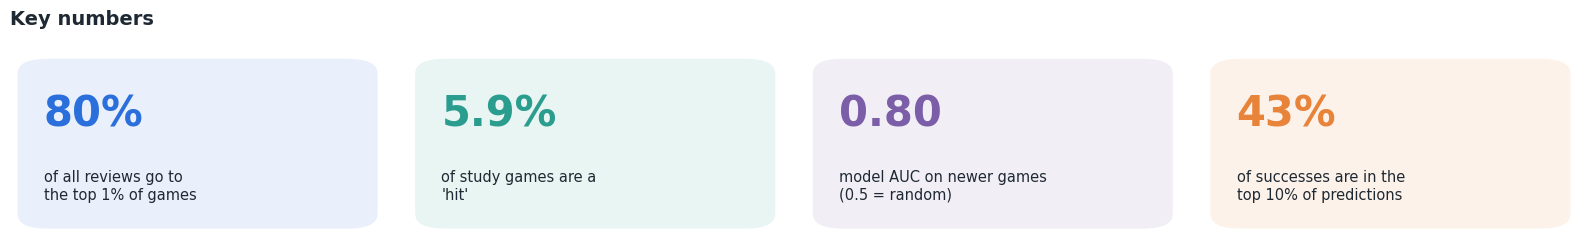

'/kaggle/working/figures/fig17_key_numbers.png'

In [45]:
kpis = [
    (pct(top1, 0), 'of all reviews go to\nthe top 1% of games', BLUE),
    (pct(overall, 1), f"of study games are a\n'{TARGET}'", TEAL),
    (f'{main["auc"]:.2f}', 'model AUC on newer games\n(0.5 = random)', PURPLE),
    (pct(capture_top, 0), 'of successes are in the\ntop 10% of predictions', ORANGE),
]
fig, axes = plt.subplots(1, 4, figsize=(16, 2.6))
for ax, (value, label, color) in zip(axes, kpis):
    ax.add_patch(FancyBboxPatch((0.02, 0.04), 0.96, 0.92, boxstyle='round,pad=0,rounding_size=0.08',
                                transform=ax.transAxes, fc=color, alpha=0.1, ec='none'))
    ax.text(0.09, 0.66, value, fontsize=30, fontweight='bold', color=color, transform=ax.transAxes, va='center')
    ax.text(0.09, 0.27, label, fontsize=10.5, color=INK, transform=ax.transAxes, va='center')
    ax.axis('off')
fig.subplots_adjust(left=0.01, right=0.99, wspace=0.06, top=0.82)
fig.suptitle('Key numbers', x=0.01, ha='left', fontsize=14, fontweight='bold')
show(fig, 'fig17_key_numbers')

In [46]:
top_f = importance.index[:3].tolist()
show_md(f"""
### 📊 What the data says (for `{TARGET}`, {len(study):,} games)

1. 🏔️ **Success is rare and concentrated.** The label covers {pct(overall)} of games; the top 1% of games hold {pct(top1, 0)} of all reviews.
2. ⚖️ **Reach and quality are different things.** Only {pct(p_quality_given_comm, 0)} of commercial hits are also well liked, which is why `hit` is much rarer than either part.
3. 🎯 **Strongest single indicators:** {', '.join(f'{f} (AUC {score.loc[f, TARGET]:.2f})' for f in strongest)}.
4. 🏷️ **Genre matters:** {best} has the highest lift ({genre_fx.loc[best, "lift"]:.1f}x), {worst} the lowest ({genre_fx.loc[worst, "lift"]:.1f}x).
5. 🤖 **Launch-time features give real but limited predictive power:** AUC {main["auc"]:.2f} on newer games; the top 10% of predictions capture {pct(capture_top, 0)} of successes. Most important features: {', '.join(top_f)}.
6. 🧩 **Biggest feature group:** {ablate.index[-1]} (removing it costs {ablate.iloc[-1]:.3f} AUC).

Results from the appendices (stability, richer features, owner buckets) are summarised at the end of the notebook.
""")


### 📊 What the data says (for `hit`, 120,629 games)

1. 🏔️ **Success is rare and concentrated.** The label covers 5.9% of games; the top 1% of games hold 80% of all reviews.
2. ⚖️ **Reach and quality are different things.** Only 26% of commercial hits are also well liked, which is why `hit` is much rarer than either part.
3. 🎯 **Strongest single indicators:** Achievements (AUC 0.73), n_categories (AUC 0.72), n_languages (AUC 0.72).
4. 🏷️ **Genre matters:** RPG has the highest lift (1.5x), Violent the lowest (0.1x).
5. 🤖 **Launch-time features give real but limited predictive power:** AUC 0.80 on newer games; the top 10% of predictions capture 43% of successes. Most important features: n_languages, n_categories, DLC count.
6. 🧩 **Biggest feature group:** Store page and extras (removing it costs 0.026 AUC).

Results from the appendices (stability, richer features, owner buckets) are summarised at the end of the notebook.


### ⚠️ Limits to keep in mind

<div style="background:#fff4ea;border-left:5px solid #e8833a;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#e8833a">⚠️ Read with care</b><br><b>Association, not cause.</b> Games that sell well can afford more languages, DLC and achievements, so those may follow success rather than cause it.<br><br><b>Owners are bucketed and estimated</b> by the dataset author from Steam data, so commercial success is approximate and ties are common. The "top 10%" commercial label covers more than 10% of games for that reason.<br><br><b>The test years have a different base rate</b> than the training years; compare AUC, and read precision and predicted chances against the test base rate.<br><br><b>Missing the biggest drivers.</b> Marketing spend, wishlists, studio reputation beyond past releases, quality of the game itself and luck are not in this data.<br><br><b>Thresholds are choices.</b> 90th percentile, 50 reviews and 80% positive are defaults; rerun with other values (see the <code>Parameters</code> cells) to check the conclusions hold.</div>

---
# 📎 Appendices

Supporting checks and extensions. They reuse variables from the main sections, so run the notebook from the top.

<a id="sa"></a>
## 🗂️ A. Data overview in detail

In [47]:
df.head(3).T.rename(columns=lambda c: f'row {c}')   # transposed: 40 columns are easier to read vertically

,row 0,row 1,row 2
AppID,2539430,496350,1034400
Name,Black Dragon Mage Playtest,Supipara - Chapter 1 Spring Has Come!,Mystery Solitaire The Black Raven
Release date,"Aug 1, 2023","Jul 29, 2016","May 6, 2019"
Estimated owners,0 - 0,0 - 20000,0 - 20000
Peak CCU,0,0,0
...,...,...,...
Categories,NaN,"Single-player,Steam Trading Cards,Steam Cloud,...","Single-player,Family Sharing"
Genres,NaN,Adventure,Casual
Tags,NaN,"Adventure,Visual Novel,Anime,Cute","Casual,Card Game,Solitaire,Puzzle,Hidden Objec..."
Screenshots,https://shared.akamai.steamstatic.com/store_it...,https://shared.akamai.steamstatic.com/store_it...,https://shared.akamai.steamstatic.com/store_it...


In [48]:
# Numeric summary. Wide gaps between the 75th percentile and the max show how skewed the data is.
df.describe().T[['count', 'mean', '50%', '75%', 'max']]

,count,mean,50%,75%,max
AppID,"125,855.000","2,032,626.605","1,949,010.000","2,938,410.000","4,437,540.000"
Peak CCU,"125,855.000",53.187,0.000,0.000,"1,013,936.000"
Required age,"125,855.000",0.165,0.000,0.000,21.000
Price,"125,855.000",4.811,2.390,5.545,999.980
Discount,"125,855.000",17.897,0.000,37.000,100.000
DLC count,"125,855.000",0.535,0.000,0.000,"3,703.000"
Metacritic score,"125,855.000",2.500,0.000,0.000,97.000
User score,"125,855.000",0.024,0.000,0.000,100.000
Positive,"125,855.000","1,018.182",4.000,35.000,"7,642,084.000"
Negative,"125,855.000",164.879,1.000,10.000,"1,173,003.000"


In [49]:
# Unique values per column: tells which columns are IDs, categories, flags or free text
unique_summary = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'unique': df.nunique(dropna=True),
    'unique_%': (df.nunique(dropna=True) / len(df) * 100).round(2),
    'missing_%': (df.isna().mean() * 100).round(2),
    'example': df.apply(lambda s: str(s.dropna().iloc[0])[:40] if s.notna().any() else ''),
}).sort_values('unique')

with pd.option_context('display.max_rows', None):
    display(unique_summary)

,dtype,unique,unique_%,missing_%,example
Movies,float64,0,0.000,100.000,
Mac,bool,2,0.000,0.000,False
Windows,bool,2,0.000,0.000,True
Linux,bool,2,0.000,0.000,False
Score rank,float64,3,0.000,99.970,99.0
Estimated owners,object,14,0.010,0.000,0 - 0
Required age,int64,15,0.010,0.000,0
User score,int64,31,0.020,0.000,0
Metacritic score,int64,73,0.060,0.000,0
Discount,int64,88,0.070,0.000,0


<a id="sb"></a>
## 🧷 B. Stability across success definitions

Sections 6 and 7 used one `TARGET`. A finding is only worth trusting if it survives a change of definition, so this section reruns the indicator tests and the model for **all four labels** and compares them.

| Check | Stable means |
|-------|--------------|
| Numeric indicators | AUC on the same side of 0.5 for every label, and at least 0.03 away from 0.5 for the weakest label |
| Genres | Lift above 1.15 for every label (or below 0.85 for every label) |
| Model features | Permutation-importance ranking is similar between labels |

<div style="background:#f4f0fa;border-left:5px solid #7b5ea7;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#7b5ea7">🧠 Why this step</b><br>The success thresholds were choices. A finding that only holds for one definition is a property of the definition, not of games, so every key result is rerun under all four labels.</div>

In [50]:
# Parameters
STABLE_MIN_SIGNAL = 0.03     # minimum |AUC - 0.5| in the weakest label
LAB_STYLE = {'commercial_success_year': (BLUE, 'o'), 'quality_success': (ORANGE, 's'),
             'engagement_success': (TEAL, '^'), 'hit': (INK, 'D')}

# B.1 Numeric indicators: same AUC table as the scorecard, now judged across labels
stab = pd.DataFrame({
    'mean_auc': score.mean(axis=1),
    'weakest_signal': (score - 0.5).abs().min(axis=1),
    'same_direction': score.gt(0.5).all(axis=1) | score.lt(0.5).all(axis=1),
})
stab['verdict'] = np.select([~stab['same_direction'], stab['weakest_signal'] >= STABLE_MIN_SIGNAL],
                            ['flips sign', 'stable'], default='weak')
stab = stab.join(score).sort_values('weakest_signal', ascending=False)
stab

,mean_auc,weakest_signal,same_direction,verdict,commercial_success_year,quality_success,engagement_success,hit
n_categories,0.691,0.158,True,stable,0.658,0.678,0.708,0.718
n_languages,0.678,0.146,True,stable,0.646,0.655,0.694,0.718
about_length,0.660,0.126,True,stable,0.632,0.626,0.720,0.661
Achievements,0.693,0.122,True,stable,0.622,0.690,0.728,0.733
Price,0.666,0.117,True,stable,0.637,0.617,0.759,0.650
DLC count,0.642,0.069,True,stable,0.569,0.631,0.681,0.685
release_year,0.466,0.058,False,flips sign,0.703,0.337,0.385,0.442
n_audio_languages,0.574,0.053,True,stable,0.565,0.553,0.589,0.591
n_platforms,0.551,0.015,True,weak,0.515,0.584,0.533,0.570
n_genres,0.531,0.014,True,weak,0.555,0.514,0.516,0.538


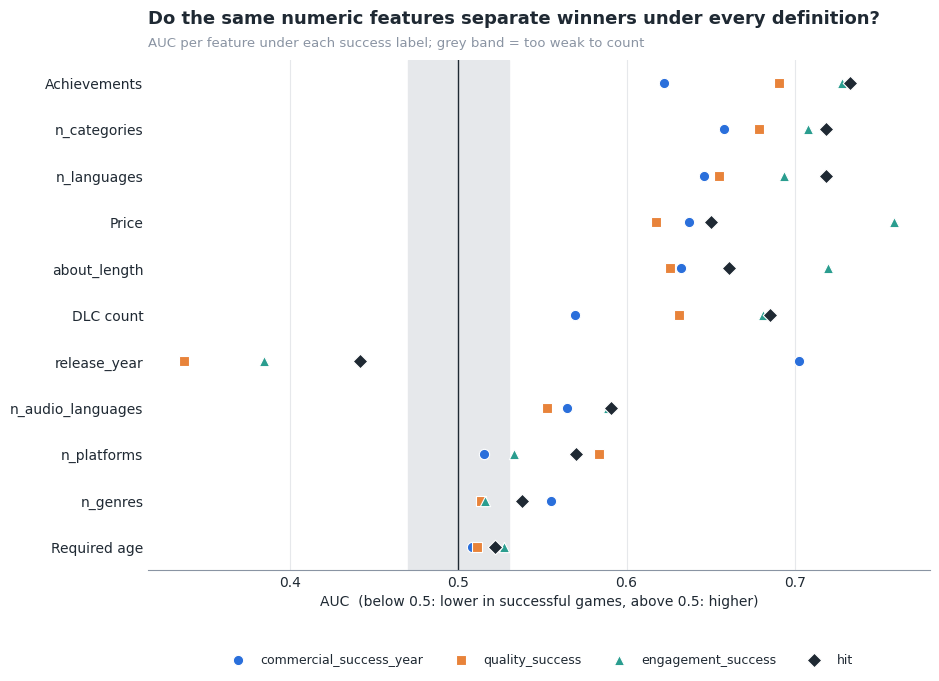

In [51]:
# One row per feature, one marker per label. Markers in the grey band are too close to 0.5 to count.
order_f = (score - 0.5).abs().mean(axis=1).sort_values().index

fig, ax = plt.subplots(figsize=(9.5, 0.45 * len(order_f) + 2))
ax.axvspan(0.5 - STABLE_MIN_SIGNAL, 0.5 + STABLE_MIN_SIGNAL, color=GRID, zorder=0)
ax.axvline(0.5, color=INK, lw=1)
for lab in LABELS:
    color, marker = LAB_STYLE[lab]
    ax.scatter(score.loc[order_f, lab], range(len(order_f)), color=color, marker=marker, s=55,
               edgecolor='white', linewidth=0.8, zorder=3, label=lab)
ax.set_yticks(range(len(order_f)))
ax.set_yticklabels(order_f)
ax.set_xlabel('AUC  (below 0.5: lower in successful games, above 0.5: higher)')
titles(ax, 'Do the same numeric features separate winners under every definition?',
       'AUC per feature under each success label; grey band = too weak to count')
ax.grid(axis='y', visible=False)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=4, fontsize=9)
plt.tight_layout()
show(fig, 'fig18_indicator_stability')

stable_num = stab.index[stab['verdict'] == 'stable'].tolist()
flip_num = stab.index[stab['verdict'] == 'flips sign'].tolist()
note(f'**Insight:** stable under all four definitions: **{", ".join(stable_num) or "none"}**. '
     f'Direction flips between definitions for: {", ".join(flip_num) or "none"}. '
     'A feature that flips (for example, helps reach but hurts quality) is a trade-off, not a recipe.')

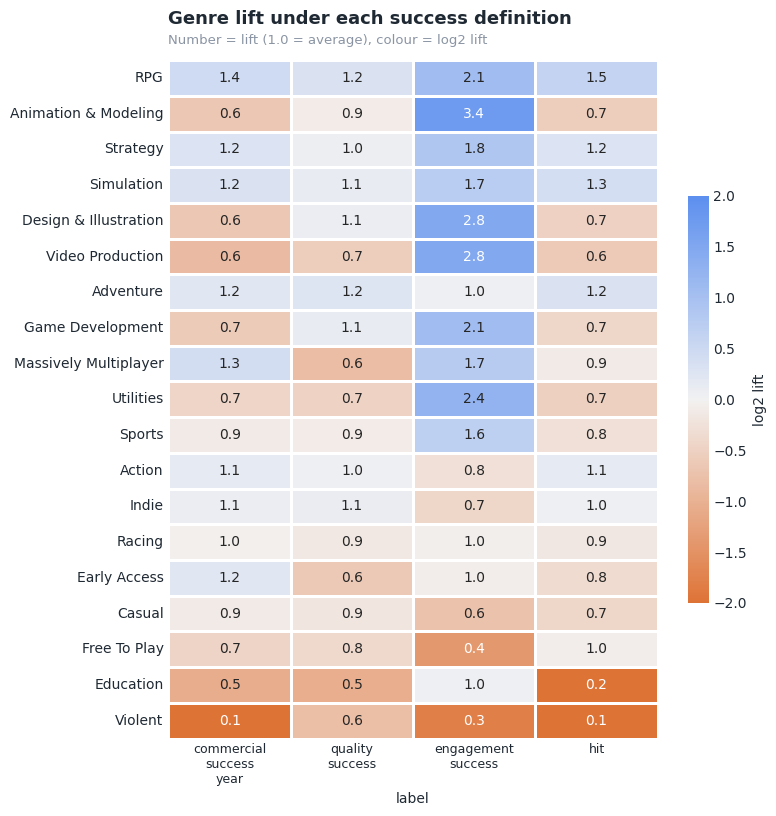

In [52]:
# B.2 Genres: lift under each label (colour = log2 lift, number = lift). Comes from the lift_all query in 6.4.
genre_lifts = (lift_all[lift_all['kind'] == 'genre']
               .pivot(index='item', columns='label', values='lift')[LABELS].dropna())
genre_lifts = genre_lifts.loc[genre_lifts.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(8, 0.34 * len(genre_lifts) + 1.8))
sns.heatmap(np.log2(genre_lifts), annot=genre_lifts, fmt='.1f', cmap=sns.diverging_palette(28, 255, s=85, l=60, as_cmap=True),
            center=0, vmin=-2, vmax=2, linewidths=1, linecolor='white', cbar_kws={'shrink': 0.6, 'label': 'log2 lift'}, ax=ax)
ax.set_xticklabels([l.replace('_', '\n') for l in genre_lifts.columns], rotation=0, fontsize=9)
titles(ax, 'Genre lift under each success definition', 'Number = lift (1.0 = average), colour = log2 lift')
ax.set_ylabel('')
ax.grid(False)
plt.tight_layout()
show(fig, 'fig19_genre_lift_stability')

genres_high = genre_lifts.index[(genre_lifts > 1.15).all(axis=1)].tolist()
genres_low = genre_lifts.index[(genre_lifts < 0.85).all(axis=1)].tolist()
note(f'**Insight:** genres that beat the average under every definition: **{", ".join(genres_high) or "none"}**. '
     f'Genres below average under every definition: **{", ".join(genres_low) or "none"}**. '
     'Genres whose colour changes across a row only help one kind of success.')

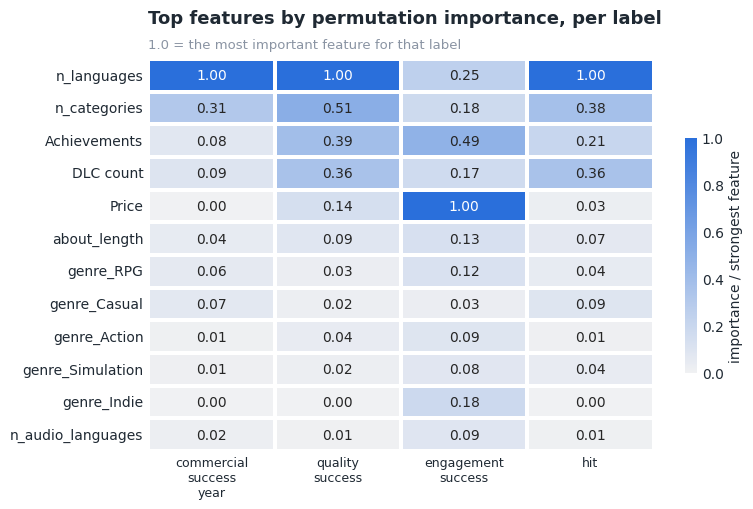

In [53]:
# B.3 Model: do the same features carry the signal under each label?
sample = np.random.RandomState(42).choice(np.where(test)[0], size=min(15_000, test.sum()), replace=False)
imp_by_label = {}
for lab in LABELS:
    mdl = fits[lab][0]
    perm_ = permutation_importance(mdl, X.iloc[sample], study[lab].astype(int).iloc[sample],
                                   scoring='roc_auc', n_repeats=3, random_state=42)
    imp_by_label[lab] = pd.Series(perm_.importances_mean, index=X.columns)
imp_df = pd.DataFrame(imp_by_label)
imp_norm = imp_df.div(imp_df.max())                # 1.0 = the most important feature for that label
top_feats = imp_norm.mean(axis=1).sort_values(ascending=False).head(12)

fig, ax = plt.subplots(figsize=(8, 5.2))
sns.heatmap(imp_norm.loc[top_feats.index].clip(lower=0), annot=True, fmt='.2f',
            cmap=sns.light_palette(BLUE, as_cmap=True), vmin=0, vmax=1, linewidths=1.5, linecolor='white',
            cbar_kws={'shrink': 0.6, 'label': 'importance / strongest feature'}, ax=ax)
ax.set_xticklabels([l.replace('_', '\n') for l in imp_norm.columns], rotation=0, fontsize=9)
titles(ax, 'Top features by permutation importance, per label', '1.0 = the most important feature for that label')
ax.grid(False)
plt.tight_layout()
show(fig, 'fig20_importance_stability')

rank_corr = imp_df.corr(method='spearman')
mean_rho = rank_corr.values[np.triu_indices(len(LABELS), 1)].mean()
note(f'**Insight:** feature-importance rankings agree between definitions with an average Spearman correlation of **{mean_rho:.2f}**. '
     f'The feature that matters most on average is **{top_feats.index[0]}**.')

<a id="sc"></a>
## 🧬 C. Richer features: store-page text and developer history

Two ideas for signal beyond the basic launch facts:

1. **Text of `About the game`.** Words are turned into TF-IDF weights, a linear model learns which words go with success, and its output becomes **one numeric feature** (`text_score`) for the main model.
2. **Developer and publisher track record.** For each game: how many games the developer released before, and how those earlier games did. This is computed in SQL with window functions over each studio's release history.

**Leakage controls (the part that is easy to get wrong):**
- The TF-IDF vocabulary and the text model are fitted on **training years only**. For training games the score is **out-of-fold** (each game is scored by a model that never saw it), so the main model does not see an over-optimistic feature.
- Track-record features only count earlier games that were released **at least a year before** the current game, so their outcomes had time to settle. Nothing from the current game or the future is used.
- Developer and publisher are matched on the exact text of the field (a studio spelled two ways counts as two).

<div style="background:#f4f0fa;border-left:5px solid #7b5ea7;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#7b5ea7">🧠 Why this step</b><br>The basic features describe the game. Two things a publisher also knows before launch are how the store page is written and how the studio's earlier games did. If they add signal, the model was missing real information; if not, the basic features already capture it.</div>

In [54]:
# Parameters
HISTORY_LAG_DAYS = 365       # earlier games must be at least this old when the current game launches

In [55]:
%%sql history <<
-- C.1 Track record of each game's developer and publisher, using only earlier releases.
--   prev_releases:  games by the same studio released on an earlier day
--   prev_hits, prev_avg_reviews, prev_hit_rate: only games released at least {{HISTORY_LAG_DAYS}} days earlier,
--   so their outcomes had time to settle. RANGE frames work on day numbers, so "N days earlier" is exact.
WITH entities AS (                      -- developer and publisher rows stacked, so one window handles both
    SELECT l.app_id, 'dev' AS role, NULLIF(TRIM(g.developers), '') AS entity,
           g.release_day, COALESCE(g.total_reviews, 0) AS reviews, CAST(l.hit AS INTEGER) AS hit
    FROM labels AS l JOIN games AS g USING (app_id)
    UNION ALL
    SELECT l.app_id, 'pub', NULLIF(TRIM(g.publishers), ''),
           g.release_day, COALESCE(g.total_reviews, 0), CAST(l.hit AS INTEGER)
    FROM labels AS l JOIN games AS g USING (app_id)
),
running AS (
    SELECT app_id, role,
           COUNT(*) OVER (PARTITION BY role, entity ORDER BY release_day
                          RANGE BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING) AS prev_releases,
           COUNT(*)     OVER settled AS n_settled,
           SUM(hit)     OVER settled AS hits_settled,
           SUM(reviews) OVER settled AS reviews_settled
    FROM entities
    WHERE entity IS NOT NULL AND release_day IS NOT NULL
    WINDOW settled AS (PARTITION BY role, entity ORDER BY release_day
                       RANGE BETWEEN UNBOUNDED PRECEDING AND {{HISTORY_LAG_DAYS}} PRECEDING)
),
per_role AS (
    SELECT app_id, role, prev_releases,
           COALESCE(hits_settled, 0)                                             AS prev_hits,
           CASE WHEN n_settled > 0 THEN reviews_settled * 1.0 / n_settled END    AS prev_avg_reviews,
           CASE WHEN n_settled > 0 THEN hits_settled * 1.0 / n_settled END       AS prev_hit_rate
    FROM running
)
SELECT l.app_id,                        -- back to one row per game; a studio with no record counts as a debut
       COALESCE(MAX(CASE WHEN p.role = 'dev' THEN p.prev_releases END), 0) AS dev_prev_releases,
       COALESCE(MAX(CASE WHEN p.role = 'dev' THEN p.prev_hits END), 0)     AS dev_prev_hits,
       MAX(CASE WHEN p.role = 'dev' THEN p.prev_avg_reviews END)           AS dev_prev_avg_reviews,
       MAX(CASE WHEN p.role = 'dev' THEN p.prev_hit_rate END)              AS dev_prev_hit_rate,
       COALESCE(MAX(CASE WHEN p.role = 'pub' THEN p.prev_releases END), 0) AS pub_prev_releases,
       COALESCE(MAX(CASE WHEN p.role = 'pub' THEN p.prev_hits END), 0)     AS pub_prev_hits,
       MAX(CASE WHEN p.role = 'pub' THEN p.prev_avg_reviews END)           AS pub_prev_avg_reviews,
       MAX(CASE WHEN p.role = 'pub' THEN p.prev_hit_rate END)              AS pub_prev_hit_rate
FROM labels AS l
LEFT JOIN per_role AS p USING (app_id)
GROUP BY l.app_id

65% of games are a developer's first release in the data


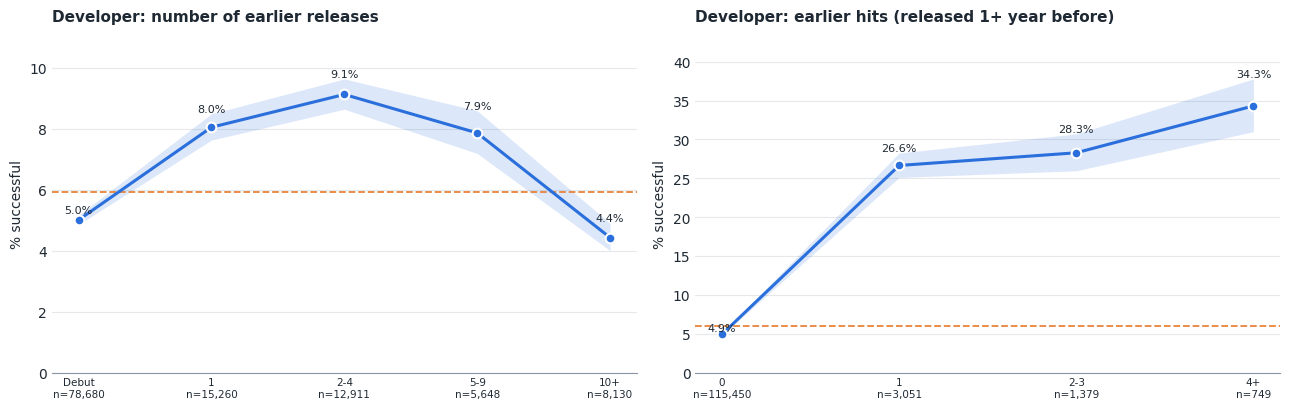

'/kaggle/working/figures/fig21_developer_track_record.png'

In [56]:
# Attach the track-record features to the study set
hist = history.set_index('app_id')
hist_cols = list(hist.columns)
for c in hist_cols:
    study[c] = study['AppID'].map(hist[c]).astype(float)

print(f'{(study["dev_prev_releases"] == 0).mean():.0%} of games are a developer\'s first release in the data')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
rate_plot(ax[0], study, 'dev_prev_releases', TARGET, [-1, 0, 1, 4, 9, 100000], ['Debut', '1', '2-4', '5-9', '10+'],
          'Developer: number of earlier releases')
rate_plot(ax[1], study, 'dev_prev_hits', TARGET, [-1, 0, 1, 3, 100000], ['0', '1', '2-3', '4+'],
          'Developer: earlier hits (released 1+ year before)')
plt.tight_layout()
show(fig, 'fig21_developer_track_record')

TF-IDF matrix: 50,646 training games x 20,000 words and word pairs


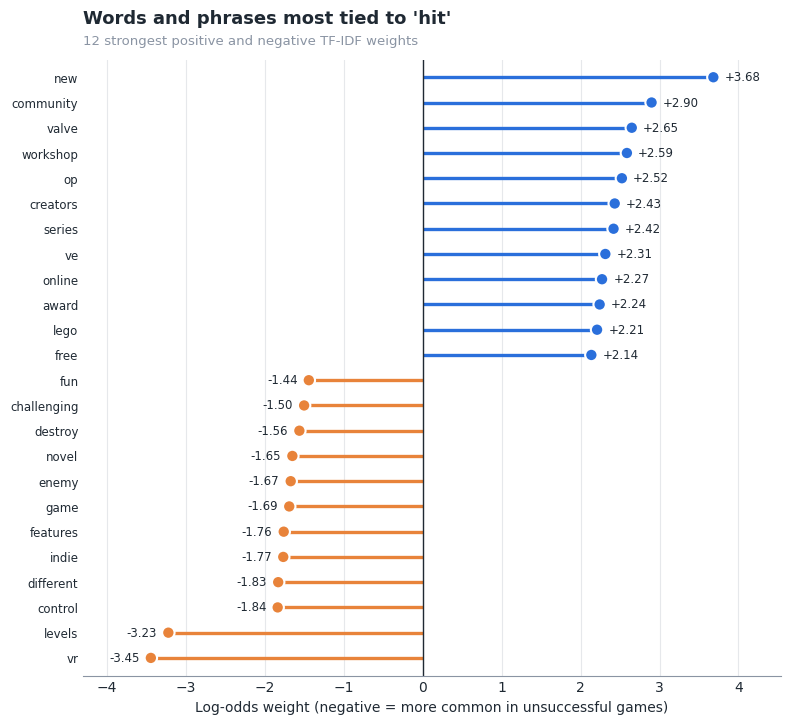

'/kaggle/working/figures/fig22_store_text_words.png'

In [57]:
# C.2 Text features
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.model_selection import KFold

docs = study['About the game'].fillna('').str.slice(0, 3000)      # cap very long pages for speed

# Vocabulary learned from the training years only
tfidf = TfidfVectorizer(max_features=20_000, min_df=30, ngram_range=(1, 2), stop_words='english',
                        sublinear_tf=True, dtype=np.float32)
T_train = tfidf.fit_transform(docs[train])
T_test = tfidf.transform(docs[test])
print(f'TF-IDF matrix: {T_train.shape[0]:,} training games x {T_train.shape[1]:,} words and word pairs')


def text_score(y, kind='binary'):
    """One number per game summarising how its store text looks like past successes.
    Training games get out-of-fold scores; test games are scored by a model fitted on all training games."""
    y_tr = np.asarray(y)[train]
    make = (lambda: LogisticRegression(C=1.0, solver='liblinear')) if kind == 'binary' else (lambda: Ridge(alpha=3.0))
    predict = (lambda m, M: m.decision_function(M)) if kind == 'binary' else (lambda m, M: m.predict(M))
    out = np.zeros(len(study))
    idx_train = np.flatnonzero(train)
    oof = np.zeros(len(idx_train))
    for tr, va in KFold(5, shuffle=True, random_state=42).split(idx_train):
        oof[va] = predict(make().fit(T_train[tr], y_tr[tr]), T_train[va])
    final = make().fit(T_train, y_tr)
    out[idx_train] = oof
    out[np.flatnonzero(test)] = predict(final, T_test)
    return pd.Series(out, index=study.index), final


# Three cheap style features
txt = study['About the game'].fillna('')
study['about_words'] = txt.str.count(r'\S+')
study['about_exclaim'] = txt.str.count('!')
study['about_caps'] = txt.str.count(r'[A-Z]') / txt.str.len().clip(lower=1)
simple_text = ['about_words', 'about_exclaim', 'about_caps']

# Which words go with the focus target? (Words reflect genre and era as much as quality.)
_, text_model = text_score(study[TARGET].astype(int).to_numpy())
words = pd.Series(text_model.coef_[0], index=tfidf.get_feature_names_out()).sort_values()
shown = pd.concat([words.head(12), words.tail(12)])

fig, ax = plt.subplots(figsize=(9, 8))
lollipop(ax, shown, center=0, fmt='{:+.2f}', label_size=8.5)
ax.set_xlabel('Log-odds weight (negative = more common in unsuccessful games)')
titles(ax, f"Words and phrases most tied to '{TARGET}'", '12 strongest positive and negative TF-IDF weights')
show(fig, 'fig22_store_text_words')

<div style="background:#fff4ea;border-left:5px solid #e8833a;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#e8833a">⚠️ Read with care</b><br>Read the word chart with care. Words that name a genre or an era ("pixel", "roguelike", "multiplayer") describe the kind of game, not good writing. Words like "award", "winner" or "bestselling" would be a red flag: they describe success that already happened (the page may have been edited after launch).</div>

In [58]:
# C.3 Does adding these features help? Same model, same time split, four feature sets, four labels.
X_ext = X.copy()
for c in hist_cols + simple_text:
    X_ext[c] = study[c]
base_cols = list(X.columns)
text_cols = simple_text + ['text_score']

feature_sets = {
    'Baseline': base_cols,
    '+ developer history': base_cols + hist_cols,
    '+ store text': base_cols + text_cols,
    '+ both': base_cols + hist_cols + text_cols,
}

fs_auc, fs_ap = {}, {}
for lab in LABELS:
    Xl = X_ext.copy()
    Xl['text_score'], _ = text_score(study[lab].astype(int).to_numpy())
    fs_auc[lab], fs_ap[lab] = {}, {}
    for name, cols in feature_sets.items():
        _, _, met = fit_eval(cols, lab, Xl)
        fs_auc[lab][name], fs_ap[lab][name] = met['auc'], met['avg_precision']
fs_auc, fs_ap = pd.DataFrame(fs_auc), pd.DataFrame(fs_ap)
display(fs_auc.round(3))
display((fs_auc - fs_auc.loc['Baseline']).round(3).rename_axis('AUC change vs baseline'))

,commercial_success_year,quality_success,engagement_success,hit
Baseline,0.633,0.782,0.907,0.805
+ developer history,0.633,0.819,0.920,0.835
+ store text,0.655,0.791,0.918,0.818
+ both,0.651,0.819,0.925,0.836


,commercial_success_year,quality_success,engagement_success,hit
AUC change vs baseline,,,,
Baseline,0.000,0.000,0.000,0.000
+ developer history,-0.000,0.037,0.013,0.030
+ store text,0.022,0.010,0.011,0.013
+ both,0.018,0.037,0.018,0.031


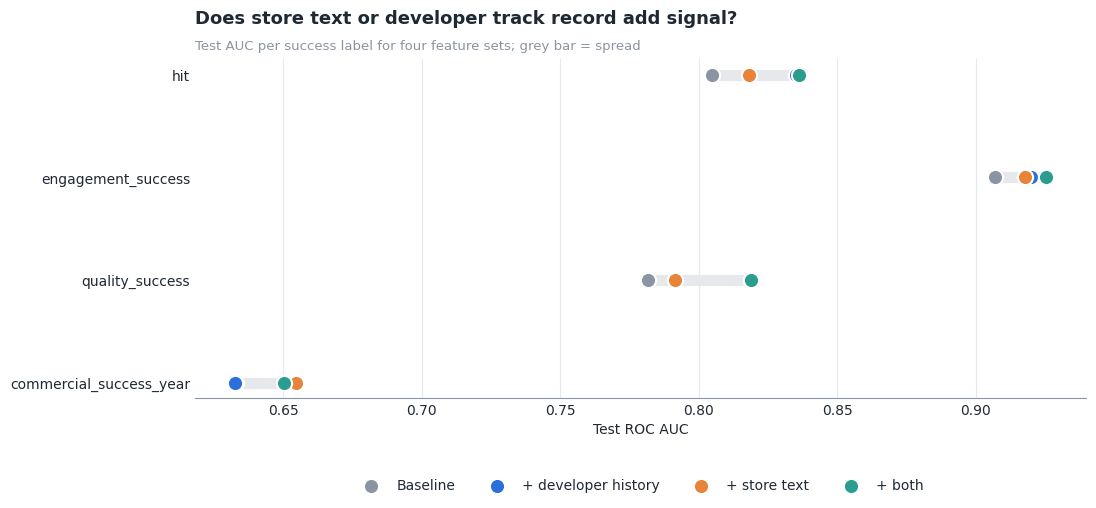

In [59]:
SET_COLORS = [MUTED, BLUE, ORANGE, TEAL]
fig, ax = plt.subplots(figsize=(11.5, 4.4))
for yi, lab in enumerate(LABELS):
    vals = fs_auc[lab]
    ax.plot([vals.min(), vals.max()], [yi, yi], color=GRID, lw=8, solid_capstyle='round', zorder=1)
    for name, color in zip(feature_sets, SET_COLORS):
        ax.scatter(vals[name], yi, color=color, s=120, zorder=3, edgecolor='white', linewidth=1.5,
                   label=name if yi == 0 else None)
ax.set_yticks(range(len(LABELS)))
ax.set_yticklabels(LABELS)
ax.set_xlabel('Test ROC AUC')
ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.2))
ax.grid(axis='y', visible=False)
titles(ax, 'Does store text or developer track record add signal?', 'Test AUC per success label for four feature sets; grey bar = spread')
show(fig, 'fig23_feature_set_comparison')

gain = (fs_auc.loc['+ both'] - fs_auc.loc['Baseline'])
gain_hist = fs_auc.loc['+ developer history', TARGET] - fs_auc.loc['Baseline', TARGET]
gain_text = fs_auc.loc['+ store text', TARGET] - fs_auc.loc['Baseline', TARGET]
note(f'**Insight:** for `{TARGET}`, developer history adds **{gain_hist:+.3f}** AUC and store text adds **{gain_text:+.3f}**; both together add **{gain[TARGET]:+.3f}**. '
     f'The largest gain over all labels is {gain.max():+.3f} (`{gain.idxmax()}`). '
     'Track record is a legitimate pre-launch signal (a studio\'s past results are public), and it says something the game\'s own attributes cannot.')

<a id="sd"></a>
## 🪜 D. Ordinal model of owner buckets

So far owners were reduced to "top 10% or not". Steam publishes owners as **ordered buckets** (0-20k, 20k-50k, 50k-100k, ...). An ordinal model uses all of that information:
for every bucket boundary it predicts the chance that a game ends **above** it (a cumulative-threshold model, Frank and Hall 2001). Adding the probabilities gives an expected bucket for each game.

**Why try it:** a regression on the owner midpoint treats the bucket edges as evenly spaced measurements, while the ordinal model only assumes the order. Whether that helps is an empirical question, so both are compared below.

Neighbouring rare buckets are merged so every class has enough training games.
Newer games have had less time to gather owners, so the **within-year** rank correlation (do games rank correctly among games released in the same year?) is the fairest single metric.

<div style="background:#f4f0fa;border-left:5px solid #7b5ea7;padding:10px 16px;margin:8px 0;border-radius:6px;color:#1f2933;line-height:1.55"><b style="color:#7b5ea7">🧠 Why this step</b><br>"Hit or not" throws away most of the owners information. Steam's buckets are ordered, so a model that predicts *how big* a game gets is a more demanding and more useful test.</div>

In [60]:
# Parameters
OWNER_MIN_CLASS = 300          # smallest number of training games per class

# D.1 Ordered classes from the owner buckets
buckets = (study[['owners_low', 'owners_high']].drop_duplicates()
           .sort_values(['owners_low', 'owners_high']).reset_index(drop=True))
bucket_id = {(lo_, hi_): i for i, (lo_, hi_) in enumerate(zip(buckets['owners_low'], buckets['owners_high']))}
raw_rank = np.array([bucket_id[t] for t in zip(study['owners_low'], study['owners_high'])])

# Merge neighbouring buckets, from the bottom up, until each class has OWNER_MIN_CLASS training games
counts = np.bincount(raw_rank[train], minlength=len(buckets))
groups, cur, acc = [], [], 0
for r, c in enumerate(counts):
    cur.append(r)
    acc += c
    if acc >= OWNER_MIN_CLASS:
        groups.append(cur)
        cur, acc = [], 0
if cur:
    if groups:
        groups[-1].extend(cur)          # leftover rare top buckets join the last class
    else:
        groups.append(cur)
mapping = np.zeros(len(buckets), dtype=int)
for gi, g in enumerate(groups):
    mapping[g] = gi
y_ord = mapping[raw_rank]
K = len(groups)


class_names = [f'{human(buckets["owners_low"][g[0]])}-{human(buckets["owners_high"][g[-1]])}' for g in groups]
thr_names = [f'> {human(buckets["owners_high"][g[-1]])}' for g in groups[:-1]]

class_share = pd.DataFrame({
    'train %': np.bincount(y_ord[train], minlength=K) / train.sum() * 100,
    'test %': np.bincount(y_ord[test], minlength=K) / test.sum() * 100,
}, index=class_names).round(1)
class_share

,train %,test %
0-0,3.300,26.700
0-20k,61.800,62.100
20k-50k,14.500,5.800
50k-100k,7.200,2.400
100k-200k,4.900,1.400
200k-500k,4.300,1.000
500k-1M,1.800,0.300
1M-2M,1.200,0.200
2M-200M,1.000,0.100


In [61]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import cohen_kappa_score

# D.2 Fit one "is it above this boundary?" model per boundary
X_ord = X_ext.copy()
X_ord['text_score'], _ = text_score(y_ord.astype(float), kind='ridge')
ord_cols = base_cols + hist_cols + text_cols

P = np.zeros((test.sum(), K - 1))
thr_auc = []
for k in range(K - 1):
    yk = (y_ord > k).astype(int)
    m = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.08, max_iter=120, min_samples_leaf=50,
                                       l2_regularization=1.0, early_stopping=False, random_state=42)
    m.fit(X_ord.loc[train, ord_cols], yk[train])
    P[:, k] = m.predict_proba(X_ord.loc[test, ord_cols])[:, 1]
    thr_auc.append(roc_auc_score(yk[test], P[:, k]) if 0 < yk[test].sum() < test.sum() else np.nan)

P = np.minimum.accumulate(P, axis=1)           # being above a higher boundary can never be likelier than above a lower one
score_ord = P.sum(axis=1)                      # expected number of boundaries passed
pred_cls = (P >= 0.5).sum(axis=1)              # most likely class (first class whose chance of being exceeded drops under 50%)
y_te = y_ord[test]

# Baseline for comparison: ordinary regression on the log owner midpoint, same features
reg = HistGradientBoostingRegressor(max_depth=4, learning_rate=0.08, max_iter=150, min_samples_leaf=50,
                                    l2_regularization=1.0, early_stopping=False, random_state=42)
reg.fit(X_ord.loc[train, ord_cols], np.log10(study.loc[train, 'owners_mid'] + 1))
score_reg = reg.predict(X_ord.loc[test, ord_cols])


def within_year_rho(s, min_games=200):
    d = pd.DataFrame({'s': s, 'y': y_te, 'yr': study.loc[test, 'release_year'].to_numpy()})
    rhos = [spearman(g['s'].to_numpy(), g['y'].to_numpy()) for _, g in d.groupby('yr') if len(g) >= min_games]
    return float(np.nanmean(rhos)) if rhos else np.nan


comparison = pd.DataFrame({
    'Ordinal model': [spearman(score_ord, y_te), within_year_rho(score_ord)],
    'Midpoint regression': [spearman(score_reg, y_te), within_year_rho(score_reg)],
}, index=['Spearman (all test games)', 'Spearman within release year'])
display(comparison.round(3))

const_cls = int(np.median(y_ord[train]))
metrics_ord = pd.Series({
    'Mean error in classes (ordinal model)': np.abs(y_te - pred_cls).mean(),
    'Mean error in classes (always predict the typical class)': np.abs(y_te - const_cls).mean(),
    'Quadratic weighted kappa (1 = perfect, 0 = chance)': cohen_kappa_score(y_te, pred_cls, weights='quadratic'),
    'Share of games predicted in the exact class': (y_te == pred_cls).mean(),
    'Share within one class': (np.abs(y_te - pred_cls) <= 1).mean(),
}).round(3)
metrics_ord.to_frame('value')

,Ordinal model,Midpoint regression
Spearman (all test games),0.310,0.523
Spearman within release year,0.333,0.546


,value
Mean error in classes (ordinal model),0.479
Mean error in classes (always predict the typical class),0.491
"Quadratic weighted kappa (1 = perfect, 0 = chance)",0.456
Share of games predicted in the exact class,0.678
Share within one class,0.906


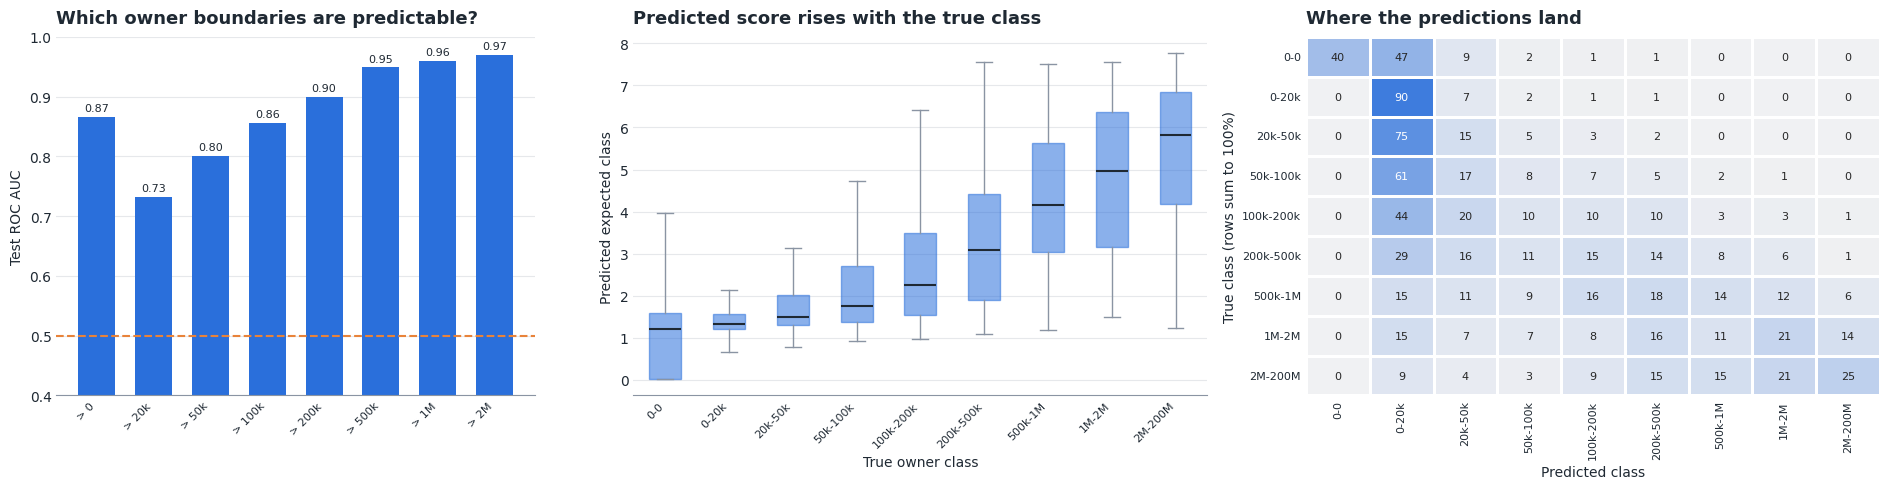

In [62]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5), gridspec_kw={'width_ratios': [1, 1.2, 1.2]})

# (a) which boundaries are predictable?
ax[0].bar(range(K - 1), thr_auc, color=BLUE, width=0.65)
ax[0].axhline(0.5, color=ORANGE, lw=1.5, ls='--')
ax[0].set_ylim(0.4, 1.0)
for i_, v in enumerate(thr_auc):
    ax[0].text(i_, v + 0.01, f'{v:.2f}', ha='center', fontsize=8)
ax[0].set_xticks(range(K - 1))
ax[0].set_xticklabels(thr_names, rotation=45, ha='right', fontsize=8)
ax[0].set_ylabel('Test ROC AUC')
ax[0].set_title('Which owner boundaries are predictable?')
ax[0].grid(axis='x', visible=False)

# (b) predicted score by true class
data = [score_ord[y_te == k] for k in range(K)]
bp = ax[1].boxplot([d_ if len(d_) else [np.nan] for d_ in data], patch_artist=True, showfliers=False,
                   medianprops=dict(color=INK, lw=1.5), whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
for box in bp['boxes']:
    box.set(facecolor=BLUE, alpha=0.55, edgecolor=BLUE)
ax[1].set_xticks(range(1, K + 1))
ax[1].set_xticklabels(class_names, rotation=45, ha='right', fontsize=8)
ax[1].set_xlabel('True owner class')
ax[1].set_ylabel('Predicted expected class')
ax[1].set_title('Predicted score rises with the true class')
ax[1].grid(axis='x', visible=False)

# (c) confusion matrix, each row sums to 100%
cm = np.zeros((K, K))
for t_, p_ in zip(y_te, pred_cls):
    cm[t_, p_] += 1
cm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1) * 100
sns.heatmap(pd.DataFrame(cm, index=class_names, columns=class_names), annot=True, fmt='.0f',
            cmap=sns.light_palette(BLUE, as_cmap=True), vmin=0, vmax=100, cbar=False,
            linewidths=1, linecolor='white', annot_kws={'fontsize': 8}, ax=ax[2])
ax[2].set_xlabel('Predicted class')
ax[2].set_ylabel('True class (rows sum to 100%)')
ax[2].set_title('Where the predictions land')
ax[2].tick_params(labelsize=8)
ax[2].grid(False)
plt.tight_layout()
show(fig, 'fig24_owner_bucket_model')

rho_o, rho_r = comparison.loc['Spearman within release year', 'Ordinal model'], comparison.loc['Spearman within release year', 'Midpoint regression']
best_thr = int(np.nanargmax(thr_auc))
worst_thr = int(np.nanargmin(thr_auc))
better = 'the ordinal model' if rho_o > rho_r else 'the midpoint regression'
note(f'**Insight:** within the same release year the ordinal model ranks games with Spearman **{rho_o:.2f}**, versus **{rho_r:.2f}** '
     f'for a regression on the log owner midpoint, so **{better}** ranks games better here. '
     f'The easiest boundary to predict is **{thr_names[best_thr]}** (AUC {thr_auc[best_thr]:.2f}) and the hardest is **{thr_names[worst_thr]}** (AUC {thr_auc[worst_thr]:.2f}). '
     f'The exact class is right for {pct(metrics_ord.iloc[3], 0)} of games and within one class for {pct(metrics_ord.iloc[4], 0)}. '
     'The diagonal in the last chart shows whether errors are near misses (good) or far misses (bad).')

## 🧾 Appendix findings

In [63]:
best_set = fs_auc[TARGET].idxmax()
show_md(f"""
### 🧷 Which findings survive every definition of success (Appendix B)
- **Stable numeric indicators:** {', '.join(stable_num) or 'none'}. Direction flips for: {', '.join(flip_num) or 'none'}.
- **Genres above average under all four definitions:** {', '.join(genres_high) or 'none'}; below average under all four: {', '.join(genres_low) or 'none'}.
- **Model features agree:** importance rankings between definitions correlate at {mean_rho:.2f} on average.

### 🧬 What the extra features add (Appendix C)
- **Developer track record:** {gain_hist:+.3f} AUC for `{TARGET}`. **Store text:** {gain_text:+.3f}. **Both:** {gain[TARGET]:+.3f}. Best feature set for this target: *{best_set}*.

### 🪜 Predicting how big a game gets (Appendix D)
- **Owner buckets:** within release years the ordinal model reaches Spearman {rho_o:.2f} and the midpoint regression {rho_r:.2f}. The ordinal model puts {pct(metrics_ord.iloc[3], 0)} of games in the exact class and {pct(metrics_ord.iloc[4], 0)} within one class.

### ⚠️ Extra limits for these analyses
- **Developer history uses exact name matches** and the labels of earlier games are measured at the end of the data, not at the time of the later launch. Only games a year or more older are used to limit this, but it is not a perfect point-in-time record.
- **Store text may have been edited after launch**, and text weights partly describe genre and era rather than quality.
""")


### 🧷 Which findings survive every definition of success (Appendix B)
- **Stable numeric indicators:** n_categories, n_languages, about_length, Achievements, Price, DLC count, n_audio_languages. Direction flips for: release_year.
- **Genres above average under all four definitions:** RPG; below average under all four: Violent.
- **Model features agree:** importance rankings between definitions correlate at 0.66 on average.

### 🧬 What the extra features add (Appendix C)
- **Developer track record:** +0.030 AUC for `hit`. **Store text:** +0.013. **Both:** +0.031. Best feature set for this target: *+ both*.

### 🪜 Predicting how big a game gets (Appendix D)
- **Owner buckets:** within release years the ordinal model reaches Spearman 0.33 and the midpoint regression 0.55. The ordinal model puts 68% of games in the exact class and 91% within one class.

### ⚠️ Extra limits for these analyses
- **Developer history uses exact name matches** and the labels of earlier games are measured at the end of the data, not at the time of the later launch. Only games a year or more older are used to limit this, but it is not a perfect point-in-time record.
- **Store text may have been edited after launch**, and text weights partly describe genre and era rather than quality.


### 🚀 Next steps
- Match developers more loosely (lowercase, strip "Inc.", "Ltd.") so a studio spelled two ways counts once.
- Add a point-in-time version of history features using review counts at the earlier game's own launch, if a dated review snapshot becomes available.
- Try sentence embeddings of `About the game` instead of TF-IDF, and compare with the text gain measured here.

In [64]:
# Bundle every saved chart into one zip (on Kaggle: Output tab -> figures.zip)
saved = sorted(f for f in os.listdir(FIG_DIR) if f.endswith('.png'))
archive = shutil.make_archive(os.path.join(os.path.dirname(os.path.abspath(FIG_DIR)), 'figures'), 'zip', FIG_DIR)
callout(f'Saved **{len(saved)}** charts as PNG in `{FIG_DIR}` and bundled them in `{archive}`.', 'result')